## Sentiment classification of Sephora skincare reviews using natural language processing

#### A comparison of traditional and transformer-based NLP models

This notebook is the first part of the project code. It includes the full workflow for loading and preparing the Sephora review and product datasets, cleaning the review text, creating three sentiment classes, EDA, and training the baseline NLP models.

The notebook also includes GPT-5-mini prompting experiments and a product recommender system prototype. The recommender system uses review text, TF-IDF, and cosine similarity to match a user’s natural language query with relevant Sephora products. The purpose of this prototype is not to build a fully deployable recommendation system, but to show how NLP techniques can be applied to a practical business use case.

The implementation code for the product recommender system was generated with the assistance of Claude and then reviewed and edited. 

Data available at: https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews 

### 1. Loading the datasets and checking shape and columns

In [1]:
# Loading and exploring the datasets

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore') # ignoring warning messages so the notebook looks cleaner

# Loading product info first
product_info = pd.read_csv("product_info.csv")

# Loading and concatenating all review files
review_files = [
    "reviews_0-250.csv",
    "reviews_250-500.csv",
    "reviews_500-750.csv",
    "reviews_750-1250.csv",
    "reviews_1250-end.csv"
]

reviews = pd.concat(
    [pd.read_csv(f) for f in review_files],
    ignore_index=True
)

In [2]:
# looking at the structure of the product info dataset
print("Product Info")
print(f"Shape: {product_info.shape}")
print(product_info.head(3))

Product Info
Shape: (8494, 27)
  product_id               product_name  brand_id brand_name  loves_count  \
0    P473671    Fragrance Discovery Set      6342      19-69         6320   
1    P473668    La Habana Eau de Parfum      6342      19-69         3827   
2    P473662  Rainbow Bar Eau de Parfum      6342      19-69         3253   

   rating  reviews            size                      variation_type  \
0  3.6364     11.0             NaN                                 NaN   
1  4.1538     13.0  3.4 oz/ 100 mL  Size + Concentration + Formulation   
2  4.2500     16.0  3.4 oz/ 100 mL  Size + Concentration + Formulation   

  variation_value  ... online_only out_of_stock  sephora_exclusive  \
0             NaN  ...           1            0                  0   
1  3.4 oz/ 100 mL  ...           1            0                  0   
2  3.4 oz/ 100 mL  ...           1            0                  0   

                                          highlights  primary_category  \
0  ['Uni

In [3]:
# looking at the structure of the reviews dataset
print("\nProduct reviews")
print(f"Shape: {reviews.shape}")
print(reviews.head(3))


Product reviews
Shape: (1094411, 19)
   Unnamed: 0    author_id  rating  is_recommended  helpfulness  \
0           0   1741593524       5             1.0          1.0   
1           1  31423088263       1             0.0          NaN   
2           2   5061282401       5             1.0          NaN   

   total_feedback_count  total_neg_feedback_count  total_pos_feedback_count  \
0                     2                         0                         2   
1                     0                         0                         0   
2                     0                         0                         0   

  submission_time                                        review_text  \
0      2023-02-01  I use this with the Nudestix “Citrus Clean Bal...   
1      2023-03-21  I bought this lip mask after reading the revie...   
2      2023-03-21  My review title says it all! I get so excited ...   

                       review_title skin_tone eye_color skin_type hair_color  \
0  Taug

### 2. Exploratory data analysis

#### 2.1 EDA for Product Info dataset

We start with looking at the product_info dataset which contains information about each product (brand, price, category, rating etc). This dataset is not the main focus of the project but it still gives useful context.

In [4]:
# How many products and columns do we have?
print(f"Number of products: {product_info.shape[0]}")
print(f"Number of columns:  {product_info.shape[1]}")

# What are the column names?
print(f"\nColumns:\n{product_info.columns.tolist()}")

Number of products: 8494
Number of columns:  27

Columns:
['product_id', 'product_name', 'brand_id', 'brand_name', 'loves_count', 'rating', 'reviews', 'size', 'variation_type', 'variation_value', 'variation_desc', 'ingredients', 'price_usd', 'value_price_usd', 'sale_price_usd', 'limited_edition', 'new', 'online_only', 'out_of_stock', 'sephora_exclusive', 'highlights', 'primary_category', 'secondary_category', 'tertiary_category', 'child_count', 'child_max_price', 'child_min_price']


In [5]:
# What is the percentage of missing values per column?

missing = (product_info.isnull().mean() * 100).round(1)
print("Missing values (% per column):")
print(missing[missing > 0])  # only printing columns that actually have missing values

Missing values (% per column):
rating                 3.3
reviews                3.3
size                  19.2
variation_type        17.0
variation_value       18.8
variation_desc        85.3
ingredients           11.1
value_price_usd       94.7
sale_price_usd        96.8
highlights            26.0
secondary_category     0.1
tertiary_category     11.7
child_max_price       67.6
child_min_price       67.6
dtype: float64


In [6]:
# Summary statistics for numeric columns

product_info[[
    'loves_count',   # How many users added this product to their wishlist?
    'rating',        # average product rating (1-5)
    'reviews',       # number of reviews the product has received
    'price_usd',     # product price in US dollar
]].describe().round(2)

,loves_count,rating,reviews,price_usd
count,8494.00,8216.00,8216.00,8494.00
mean,29179.57,4.19,448.55,51.66
std,66092.12,0.52,1101.98,53.67
min,0.00,1.00,1.00,3.00
25%,3758.00,3.98,26.00,25.00
50%,9880.00,4.29,122.00,35.00
75%,26841.25,4.53,418.00,58.00
max,1401068.00,5.00,21281.00,1900.00


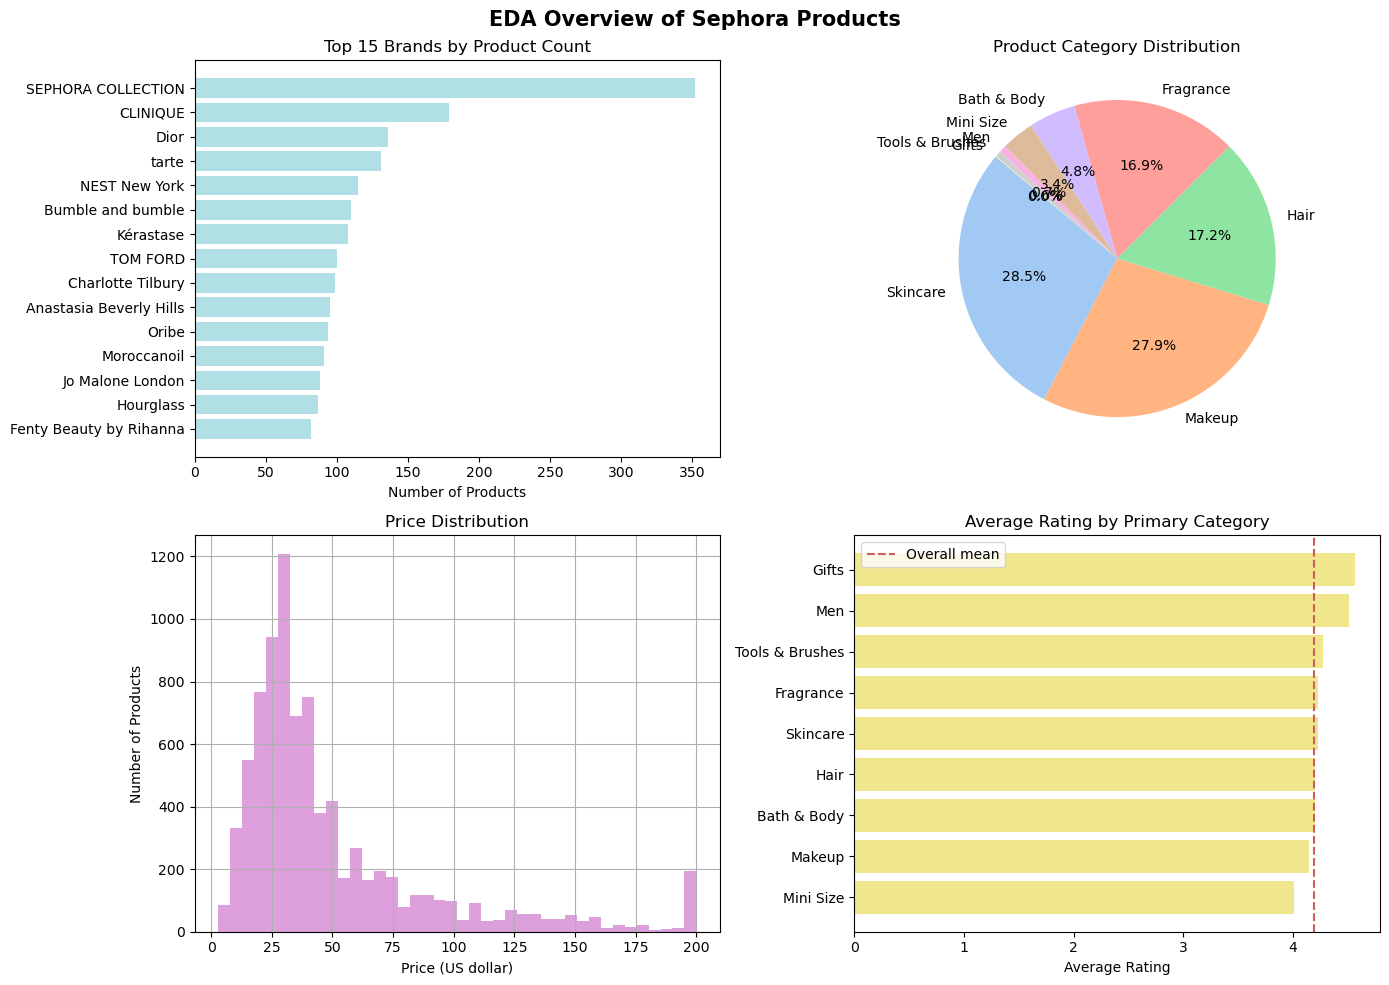

In [7]:
# Visualisations — we are putting 4 plots in one cell
# creating a 2x2 grid of plots to get a nice visual overview of the most interesting aspects of the product dataset

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('EDA Overview of Sephora Products', fontsize=15, fontweight='bold')

# Plot 1: Top 15 brands by number of products

# Which brands have the most products listed on Sephora? (a few big brands likely dominate)
top_brands = product_info['brand_name'].value_counts().head(15)
axes[0,0].barh(top_brands.index[::-1], top_brands.values[::-1], color='powderblue')
axes[0,0].set_title('Top 15 Brands by Product Count')
axes[0,0].set_xlabel('Number of Products')

# -------------------------------------------------------------------------------------------------------------------------------------------

# Plot 2: What product categories are in the dataset?

# Is skincare actually the largest product category? 
cat_counts = product_info['primary_category'].value_counts()
axes[0,1].pie(
    cat_counts.values,
    labels=cat_counts.index,
    autopct='%1.1f%%',       #to show percentage on each slice
    startangle=140,
    colors=sns.color_palette('pastel')
)
axes[0,1].set_title('Product Category Distribution')

# -------------------------------------------------------------------------------------------------------------------------------------------

# Plot 3: How are product prices distributed?

# We stop the x-axis at 200 so that a few very expensive products would not squash the rest of the plot
price_data = product_info['price_usd'].dropna()
price_data.clip(upper=200).hist(ax=axes[1,0], bins=40, 
                                 color='plum')
axes[1,0].set_title('Price Distribution')
axes[1,0].set_xlabel('Price (US dollar)')
axes[1,0].set_ylabel('Number of Products')

# -------------------------------------------------------------------------------------------------------------------------------------------

# Plot 4: Which categories get the highest ratings?

# We calculate the mean rating per category and add a red line showing the overall average rating as a benchmark
avg_rating = product_info.groupby('primary_category')['rating'].mean().sort_values()
axes[1,1].barh(avg_rating.index, avg_rating.values, color='khaki')
axes[1,1].set_title('Average Rating by Primary Category')
axes[1,1].set_xlabel('Average Rating')
axes[1,1].axvline(
    product_info['rating'].mean(),  # overall mean rating
    color='indianred', linestyle='--', 
    label='Overall mean'
)
axes[1,1].legend()

plt.tight_layout()
plt.show()

In [8]:
# Ingredient mentions and average rating

# skincare reviews often mention ingredients
# here we check whether reviews mentioning specific ingredients tend to have higher or lower ratings

ingredients = [
    'retinol', 'niacinamide', 'hyaluronic acid', 'glycolic acid',
    'salicylic acid', 'vitamin c', 'spf', 'ceramide', 'squalane',
    'fragrance', 'peptide', 'benzoyl peroxide', 'azelaic acid',
    'centella', 'lactic acid', 'glycerin'
]

# making sure we only use reviews with text and rating
ingredient_rating_df = reviews.dropna(subset=['review_text', 'rating']).copy()

# overall average rating, used as a comparison line
overall_avg_rating = ingredient_rating_df['rating'].mean()

print("Average rating for reviews mentioning specific ingredients:\n")
print(f"{'ingredient':<18} {'reviews':>10} {'avg rating':>12}")
print("-" * 45)

ingredient_names = []
ingredient_avg_ratings = []
ingredient_review_counts = []

for ingredient in ingredients:
    
    # selecting reviews that mention the ingredient
    mentions = ingredient_rating_df[
        ingredient_rating_df['review_text'].str.contains(
            ingredient,
            case=False,
            na=False,
            regex=False
        )
    ]
    
    # only showing ingredients with enough reviews
    if len(mentions) > 10:
        
        avg_rating = mentions['rating'].mean()
        
        print(f"{ingredient:<18} {len(mentions):>10,} {avg_rating:>12.2f}")
        
        ingredient_names.append(ingredient)
        ingredient_avg_ratings.append(avg_rating)
        ingredient_review_counts.append(len(mentions))

Average rating for reviews mentioning specific ingredients:

ingredient            reviews   avg rating
---------------------------------------------
retinol                18,282         4.50
niacinamide             5,460         4.48
hyaluronic acid         8,561         4.47
glycolic acid           2,424         4.40
salicylic acid          4,094         4.37
vitamin c              16,728         4.39
spf                    23,322         4.40
ceramide                2,101         4.60
squalane                2,320         4.45
fragrance              32,551         4.15
peptide                 4,214         4.53
benzoyl peroxide        1,146         4.49
azelaic acid              430         4.41
centella                  170         4.33
lactic acid             2,553         4.48
glycerin                  497         3.95


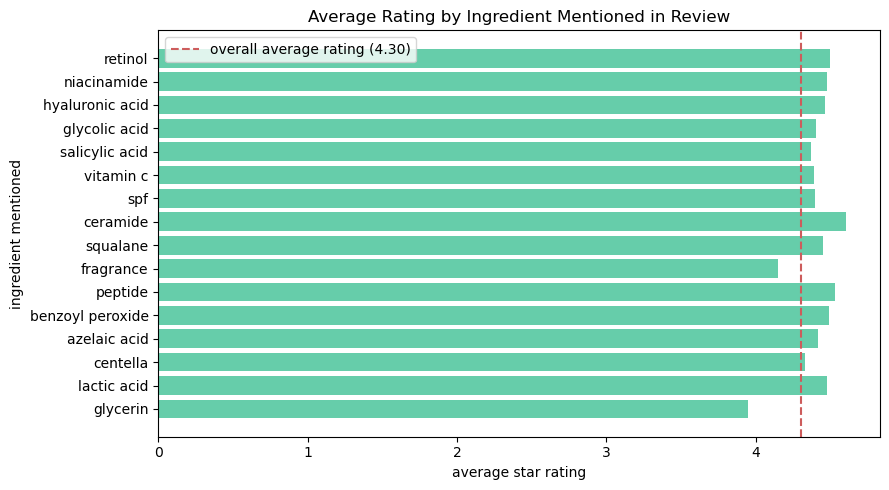

In [9]:
# Plotting average rating by ingredient mentioned

plt.figure(figsize=(9, 5))

plt.barh(
    ingredient_names[::-1],
    ingredient_avg_ratings[::-1],
    color='mediumaquamarine'
)

# adding the overall average rating as a comparison line
plt.axvline(
    overall_avg_rating,
    color='indianred',
    linestyle='--',
    label=f'overall average rating ({overall_avg_rating:.2f})'
)

plt.title('Average Rating by Ingredient Mentioned in Review')
plt.xlabel('average star rating')
plt.ylabel('ingredient mentioned')
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# Top brands by average product rating

# We only keep rows where brand_name and rating are not missing
brand_ratings = product_info.dropna(subset=['brand_name', 'rating'])

# Grouping by brand and calculating:
# - average rating
# - number of products per brand
brand_rating_summary = brand_ratings.groupby('brand_name').agg(
    avg_rating=('rating', 'mean'),
    product_count=('product_id', 'count')
).reset_index()

# To make the result more reliable, we only keep brands with at least 10 products
brand_rating_summary = brand_rating_summary[
    brand_rating_summary['product_count'] >= 10
]

# Sorting brands from highest to lowest average rating
top_brands_by_rating = brand_rating_summary.sort_values(
    by='avg_rating',
    ascending=False
).head(15)

# Checking the result
display(top_brands_by_rating)

,brand_name,avg_rating,product_count
161,MARA,4.823860,10
26,BondiBoost,4.776950,34
140,Kate McLeod,4.751583,12
297,maude,4.740100,12
185,Nutrafol,4.724500,10
237,StriVectin,4.658125,24
84,FaceGym,4.646450,16
282,alpyn beauty,4.644946,13
253,The Nue Co.,4.590675,12
53,Curlsmith,4.573124,42


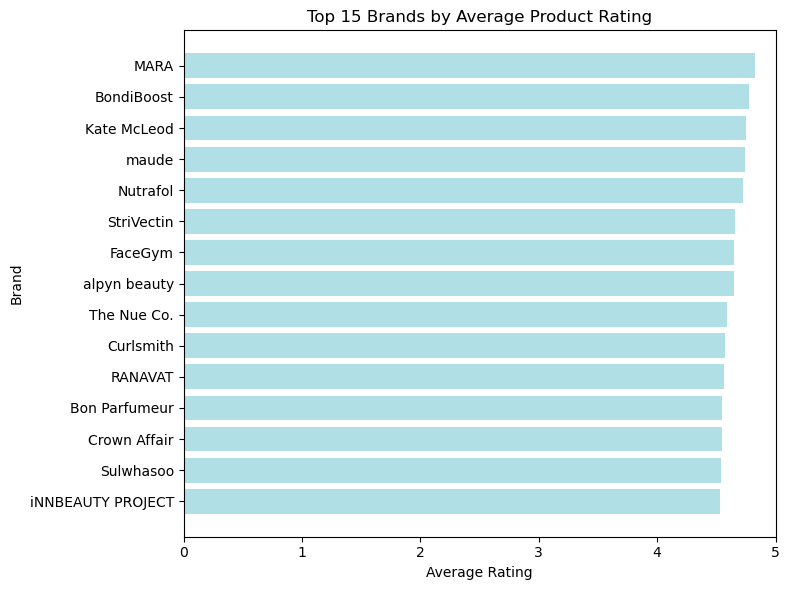

In [11]:
# Plot: Top 15 brands by average rating

plt.figure(figsize=(8, 6))

plt.barh(
    top_brands_by_rating['brand_name'][::-1],
    top_brands_by_rating['avg_rating'][::-1],
    color='powderblue'
)

plt.title('Top 15 Brands by Average Product Rating')
plt.xlabel('Average Rating')
plt.ylabel('Brand')

plt.xlim(0, 5)

plt.tight_layout()
plt.show()

In [12]:
# Worst brands by average product rating

# We only keep rows where brand_name and rating are not missing
brand_ratings = product_info.dropna(subset=['brand_name', 'rating'])

# Grouping by brand and calculating:
# - average rating
# - number of products per brand
brand_rating_summary = brand_ratings.groupby('brand_name').agg(
    avg_rating=('rating', 'mean'),
    product_count=('product_id', 'count')
).reset_index()

# Keeping only brands with at least 10 products
# This makes the result more reliable
brand_rating_summary = brand_rating_summary[
    brand_rating_summary['product_count'] >= 10
]

# Sorting brands from lowest to highest average rating
worst_brands_by_rating = brand_rating_summary.sort_values(
    by='avg_rating',
    ascending=True
).head(15)

# Checking the result
display(worst_brands_by_rating)

,brand_name,avg_rating,product_count
184,NuFACE,3.538150,12
82,FORVR Mood,3.597809,23
232,Slip,3.633153,15
119,INC.redible,3.686033,15
91,Floral Street,3.698142,19
0,19-69,3.721214,14
198,PHLUR,3.768432,19
21,Bio Ionic,3.770977,13
122,Isle of Paradise,3.801700,19
177,NAILS INC.,3.823904,25


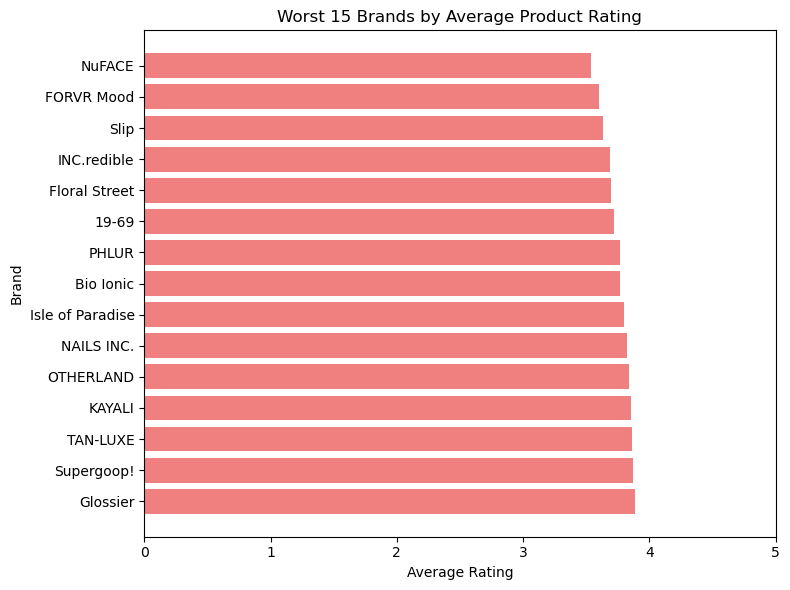

In [13]:
# Worst 15 brands by average product rating

plt.figure(figsize=(8, 6))

plt.barh(
    worst_brands_by_rating['brand_name'][::-1],
    worst_brands_by_rating['avg_rating'][::-1],
    color='lightcoral'
)

plt.title('Worst 15 Brands by Average Product Rating')
plt.xlabel('Average Rating')
plt.ylabel('Brand')

plt.xlim(0, 5)

plt.tight_layout()
plt.show()

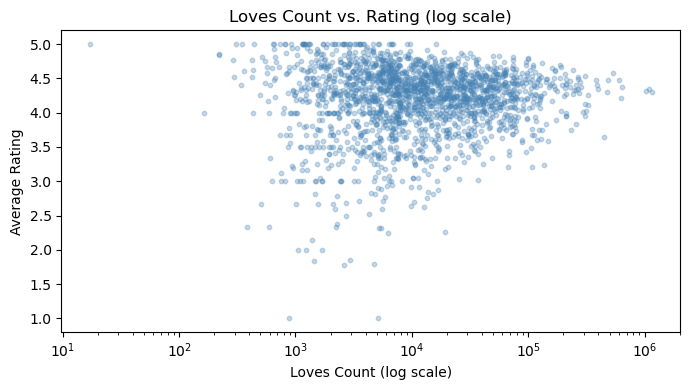

Correlation between loves_count and rating: 0.042


In [14]:
# Does popularity actually relate to ratings?

sample = product_info.dropna(subset=['loves_count', 'rating']).sample(2000, random_state=42)

plt.figure(figsize=(7, 4))
plt.scatter(sample['loves_count'], sample['rating'], 
            alpha=0.3,        # transparency so overlapping points are visible
            color='steelblue', 
            s=10)             # small point size
plt.xscale('log')             # log scale on x-axis
plt.title('Loves Count vs. Rating (log scale)')
plt.xlabel('Loves Count (log scale)')
plt.ylabel('Average Rating')
plt.tight_layout()
plt.show()

# Finally, we compute the actual correlation coefficient.
# A value close to 0 means little to no linear relationship.
# A value close to 1 or -1 means a strong relationship.
corr = product_info[['loves_count', 'rating']].corr().iloc[0, 1]
print(f"Correlation between loves_count and rating: {corr:.3f}")

#### 2.2 EDA for Reviews dataset

This is our main dataset, which contains ~1.1 million reviews from real Sephora customers. Each review has a text body, a star rating, and some metadata about the reviewer. Before we start any NLP modelling, it is important to get a good understanding of this data.

In [15]:
# Basic overview

# How many reviews and columns do we have?
print(f"Number of reviews: {reviews.shape[0]:,}")
print(f"Number of columns: {reviews.shape[1]}")

# What types of variables do we have?
print(f"\nColumn names:\n{reviews.columns.tolist()}")
print(f"\nData types:\n{reviews.dtypes}")

Number of reviews: 1,094,411
Number of columns: 19

Column names:
['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd']

Data types:
Unnamed: 0                    int64
author_id                    object
rating                        int64
is_recommended              float64
helpfulness                 float64
total_feedback_count          int64
total_neg_feedback_count      int64
total_pos_feedback_count      int64
submission_time              object
review_text                  object
review_title                 object
skin_tone                    object
eye_color                    object
skin_type                    object
hair_color                   object
product_id                   object
product_name                 objec

In [16]:
# What is the percentage of missing values per column?

# This is important for review_text — if too many reviews have no text, then that is a problem for our NLP task

missing = (reviews.isnull().mean() * 100).round(1)
print("Missing values (% per column):")
print(missing[missing > 0])

Missing values (% per column):
is_recommended    15.3
helpfulness       51.3
review_text        0.1
review_title      28.4
skin_tone         15.6
eye_color         19.2
skin_type         10.2
hair_color        20.7
dtype: float64


In [17]:
# Summary statistics for numeric columns

reviews[[
    'rating',                     # star rating 1-5 (which will be our target variable)
    'is_recommended',             # did the reviewer recommend the product?
    'helpfulness',                # ratio of helpful votes
    'total_feedback_count',       # total number of helpful/unhelpful votes
    'price_usd',                  # price of the reviewed product
]].describe().round(2)

#mean of all ratings is very high, 4.3

,rating,is_recommended,helpfulness,total_feedback_count,price_usd
count,1094411.00,926423.00,532819.00,1094411.00,1094411.00
mean,4.30,0.84,0.77,4.18,49.01
std,1.15,0.37,0.32,22.72,40.04
min,1.00,0.00,0.00,0.00,3.00
25%,4.00,1.00,0.65,0.00,25.00
50%,5.00,1.00,0.93,0.00,39.00
75%,5.00,1.00,1.00,3.00,62.00
max,5.00,1.00,1.00,5464.00,1900.00


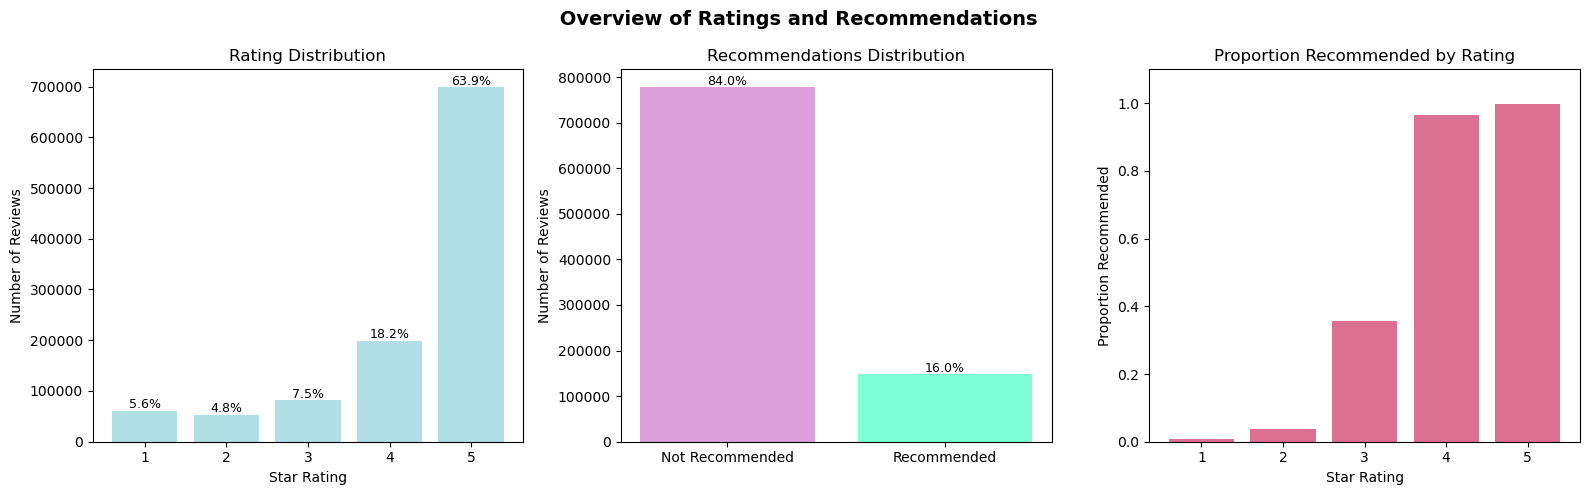


Rating distribution (%):
1     5.6
2     4.8
3     7.5
4    18.2
5    63.9
Name: rating, dtype: float64


In [18]:
# Visualisation for ratings and recommendations

# This grid focuses on our target variable (rating) and the related 'is_recommended' column
# Understanding the class distribution is important because heavily imbalanced classes can mislead our models into ignoring minority classes

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(' Overview of Ratings and Recommendations', fontsize=14, fontweight='bold')

# Plot 1: Rating distribution 

# We expect most reviews to be 4 or 5 stars
# This is typical of beauty retail where unhappy customers often do not bother leaving a review ("positivity bias")

rating_counts = reviews['rating'].value_counts().sort_index()
axes[0].bar(rating_counts.index, rating_counts.values, 
            color='powderblue')
axes[0].set_title('Rating Distribution')
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Number of Reviews')
axes[0].set_xticks([1, 2, 3, 4, 5])

# adding percentages on top of each bar
for i, (val, count) in enumerate(zip(rating_counts.index, rating_counts.values)):
    pct = count / len(reviews) * 100
    axes[0].text(val, count + 5000, f'{pct:.1f}%', ha='center', fontsize=9)

#--------------------------------------------------------------------------------------------------------------------------------------------

# Plot 2: Is_recommended distribution

# 'is_recommended' is a yes/no column and we expect it to align closely with high ratings (4-5 stars)

rec_counts = reviews['is_recommended'].value_counts()
axes[1].bar(['Not Recommended', 'Recommended'], 
            rec_counts.values, 
            color=['plum', 'aquamarine'])
axes[1].set_title('Recommendations Distribution')
axes[1].set_ylabel('Number of Reviews')

# adding count labels on bars
for i, count in enumerate(rec_counts.values):
    pct = count / rec_counts.sum() * 100
    axes[1].text(i, count + 5000, f'{pct:.1f}%', ha='center', fontsize=9)

#--------------------------------------------------------------------------------------------------------------------------------------------

# Plot 3: Average 'is_recommended' per rating

# How well does 'is_recommended' align with rating?
# We use this to validate the quality of our target variable

rec_by_rating = reviews.groupby('rating')['is_recommended'].mean()
axes[2].bar(rec_by_rating.index, rec_by_rating.values, 
            color='palevioletred')
axes[2].set_title('Proportion Recommended by Rating')
axes[2].set_xlabel('Star Rating')
axes[2].set_ylabel('Proportion Recommended')
axes[2].set_xticks([1, 2, 3, 4, 5])
axes[2].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

# printing exact percentages for reference
print("\nRating distribution (%):")
print((rating_counts / len(reviews) * 100).round(1))

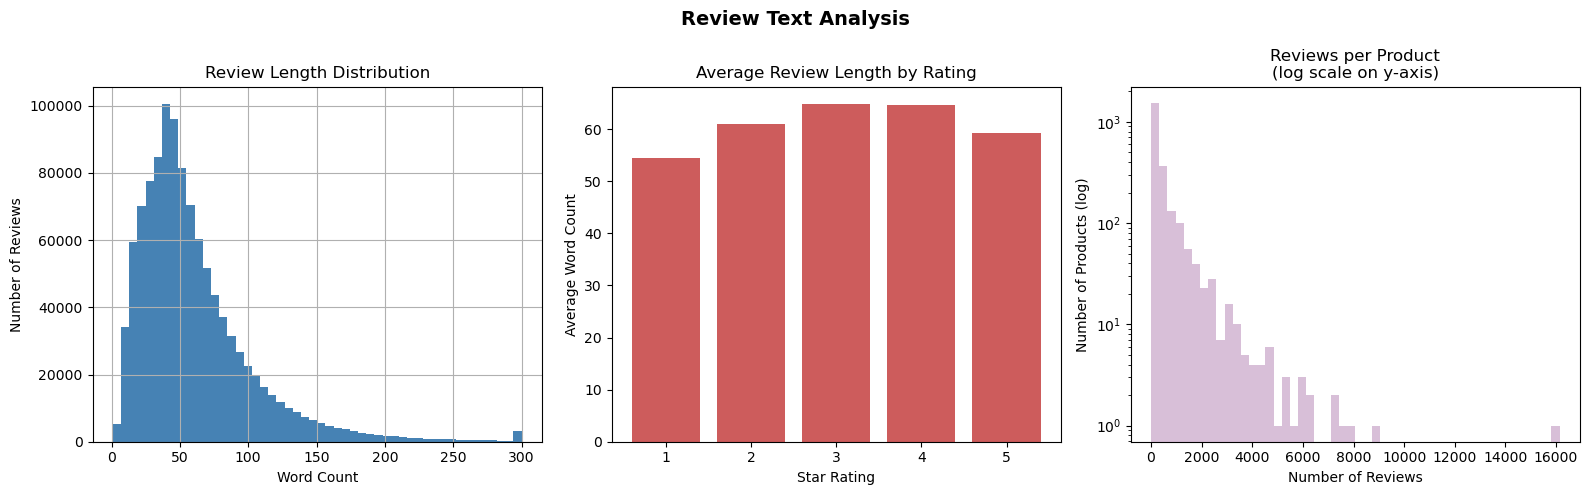

Review length statistics (words):
count    1092967.0
mean          60.5
std           43.5
min            1.0
25%           32.0
50%           50.0
75%           76.0
max         1216.0
Name: review_length, dtype: float64


In [19]:
# Visualisation of review text analysis

# Now we look at the text. Before doing any NLP, it is good to understand how long reviews are, since  this affects preprocessing and model choices
# For example, BERT has a maximum input length of 512 tokens

# First, we compute review length in words.
# We drop rows where review_text is missing before doing this.
reviews['review_length'] = reviews['review_text'].dropna().apply(
    lambda x: len(str(x).split())   # splitting by whitespace and count words
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Review Text Analysis', fontsize=14, fontweight='bold')

# Plot 1: Distribution of review lengths
# We stop at 300 words so extreme outliers do not compress the rest of the chart into an messy spike
reviews['review_length'].clip(upper=300).hist(
    ax=axes[0], bins=50, color='steelblue'
)
axes[0].set_title('Review Length Distribution')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Number of Reviews')

#--------------------------------------------------------------------------------------------------------------------------------------------

# Plot 2: Average review length per star rating
# Do people who give low ratings write longer reviews? (because egative reviews are often more detailed and emotional)
avg_len_by_rating = reviews.groupby('rating')['review_length'].mean()
axes[1].bar(avg_len_by_rating.index, avg_len_by_rating.values, 
            color='indianred')
axes[1].set_title('Average Review Length by Rating')
axes[1].set_xlabel('Star Rating')
axes[1].set_ylabel('Average Word Count')
axes[1].set_xticks([1, 2, 3, 4, 5])

#--------------------------------------------------------------------------------------------------------------------------------------------

# Plot 3: Number of reviews per product (log scale)
# Some products have thousands of reviews, others have just one (log scale makes more readable)
reviews_per_product = reviews.groupby('product_id').size()
axes[2].hist(reviews_per_product, bins=50, 
             color='thistle', log=True)
axes[2].set_title('Reviews per Product\n(log scale on y-axis)')
axes[2].set_xlabel('Number of Reviews')
axes[2].set_ylabel('Number of Products (log)')

plt.tight_layout()
plt.show()

# printing review length stats for reference
print("Review length statistics (words):")
print(reviews['review_length'].describe().round(1))

### 3. Data preprocessing

We will do the data preprocessing in the following steps: 

1. Drop reviews with missing text
2. Create sentiment labels (positive / neutral / negative)
3. Lowercase all text
4. Tokenize (split into individual words)
5. Remove stopwords
6. Lemmatize (reduce words to their base dictionary form)
7. Rejoin tokens into a single cleaned string

In [20]:
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from collections import Counter

# downloading all the NLTK resources we need
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# initializing stopwords and the lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

print("All preprocessing tools loaded")

All preprocessing tools loaded


[nltk_data] Downloading package punkt to
[nltk_data]     /Users/helenavalk/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/helenavalk/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/helenavalk/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/helenavalk/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/helenavalk/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


##### 1. Drop reviews with missing text

In [21]:
# Before dropping anything, we check how many reviews have missing review_text values

missing_review_text = reviews['review_text'].isna().sum()

print("Number of reviews with missing review text:")
print(missing_review_text)

print()

print("Percentage of reviews with missing review text:")
print(round((missing_review_text / len(reviews)) * 100, 2), "%")

Number of reviews with missing review text:
1444

Percentage of reviews with missing review text:
0.13 %


In [22]:
# Dropping reviews with no text

# because some reviews have a star rating but no written text so these are useless for NLP

print(f"Reviews before dropping missing text: {len(reviews):,}")
reviews = reviews.dropna(subset=['review_text'])
print(f"Reviews after dropping missing text:  {len(reviews):,}")

Reviews before dropping missing text: 1,094,411
Reviews after dropping missing text:  1,092,967


##### 2. Creating sentiment labels

In [23]:
# we group ratings into 3 sentiment classes:
#   0 = negative  (1 or 2 stars)
#   1 = neutral   (3 stars)
#   2 = positive  (4 or 5 stars)

# this is more nuanced than binary (positive/negative) but more manageable than full 5-class
# it also maps naturally to how people think about reviews

def sentiment_label(rating):
    
    #ratings 1 and 2 are negative
    if rating <= 2:
        return 0
    
    #rating 3 is neutral
    elif rating == 3:
        return 1
    
    #ratings 4 and 5 are positive
    else:
        return 2

#applying the function to create the sentiment column
reviews['sentiment'] = reviews['rating'].apply(sentiment_label)

#checking the class distribution
print("Sentiment label counts:")
print(reviews['sentiment'].value_counts().sort_index())

print("\nClass labels: 0 = negative, 1 = neutral, 2 = positive")

print("\nAs percentages:")
print((reviews['sentiment'].value_counts(normalize=True).sort_index() * 100).round(1))

Sentiment label counts:
0    114061
1     81752
2    897154
Name: sentiment, dtype: int64

Class labels: 0 = negative, 1 = neutral, 2 = positive

As percentages:
0    10.4
1     7.5
2    82.1
Name: sentiment, dtype: float64


##### 3. Fixed! Taking a sample of our dataset for training speed

The class imbalance in our data is so severe — 64% of reviews are 5-star so to fix this we create a balanced sample where each sentiment class has exactly the same number of reviews. We tried it before with a stratified sample (sampling proportionally from each class so the class balance is preserved) but this produced very bad results, like always defaulting to predicting the majority class, so we'll try like this instead. 

This is random undersampling!! We are taking the smallest class (negative, which is about 7,000 reviews) and reducing the larger classes (neutral and positive) down to match it. So we are kind of throwing away data from the majority class to create balance.

In [24]:
# creating a balanced sample instead of one that represents the actual structure of the data

# we find the size of the smallest class and sample that many from each class
# we also increase the total sample to 100,000 reviews for better model performance

# because negative and neutral classes are much smaller than positive, the total sample will be limited by the smallest class

# first checking how many reviews are available per sentiment class
print("Available reviews per sentiment class:")
print(reviews['sentiment'].value_counts().sort_index())
print("\nClass labels: 0 = negative, 1 = neutral, 2 = positive")

# finding the size of the smallest class
# we cap it at 33,333 so we get close to 100,000 total reviews (3 x 33,333)
min_class_size = min(reviews['sentiment'].value_counts().min(), 33333)
print(f"\Ssampling {min_class_size:,} reviews from each class")

# sampling equally from each class
reviews_sample = reviews.groupby('sentiment', group_keys=False).apply(
    lambda x: x.sample(min_class_size, random_state=42)
).reset_index(drop=True)

print(f"\ntotal sample size: {len(reviews_sample):,}")
print("\nsentiment distribution in balanced sample:")
print(reviews_sample['sentiment'].value_counts().sort_index())

Available reviews per sentiment class:
0    114061
1     81752
2    897154
Name: sentiment, dtype: int64

Class labels: 0 = negative, 1 = neutral, 2 = positive
\Ssampling 33,333 reviews from each class

total sample size: 99,999

sentiment distribution in balanced sample:
0    33333
1    33333
2    33333
Name: sentiment, dtype: int64


##### previous code with stratified sample: 

#with over 1 million reviews, training on the full dataset would take hours so we take a stratified sample of 50,000 reviews instead
#stratified means we sample proportionally from each class so the class balance is preserved

#we use random_state = 42 so that the results are reproducible

reviews_sample = reviews.sample(50000, random_state=42).reset_index(drop=True)

print(f"Sample size: {len(reviews_sample):,}")
print("\nSentiment distribution in sample:")
print(reviews_sample['sentiment'].value_counts().sort_index())

print("\nClass labels: 0 = negative, 1 = neutral, 2 = positive")

##### 4. Defining the classic function for cleaning, tokenizing, lemmatizing

This function cleans text for classical models like Naive Bayes and Logistic Regression. Because these models work with word frequencies, we want to remove as much noise as possible

In [25]:
# we define one function that takes a raw review and returns a cleaned version
# same approach as in the exercise classes

def clean_text(text):

    # turning the text into a string (in case of any non-string values)
    text = str(text)

    # converting all text to lowercase
    text = text.lower()

    # removing URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # removing punctuation, numbers, and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # normalizing whitespace (removing extra spaces)
    text = re.sub(r'\s+', ' ', text).strip()

    # tokenizing — splitting the string into individual words
    tokens = word_tokenize(text)

    # removing stopwords and lemmatizing in one loop
    cleaned_tokens = []
    for word in tokens:

        # skipping stopwords like "the", "and", "i" — they carry no sentiment signal
        if word not in stop_words:

            # lemmatizing reduces words to their base form
            # such as "loving" → "love" etc
            lemma = lemmatizer.lemmatize(word)
            cleaned_tokens.append(lemma)

    # rejoining the tokens back into a single string
    return ' '.join(cleaned_tokens)


# testing the function on a few reviews before applying it to everything
example = reviews_sample['review_text'].iloc[0]
print("Original:  ", example)
print("\nCleaned:   ", clean_text(example))

Original:   I received this from Influenster as part of a campaign and was thrilled because I normally love Clinique products. But, I used it for a few weeks and I wish it worked better for me. The cream itself has a nice texture and feels great and refreshing. I started using it as a night and day all-purpose moisturizer but noticed it was too heavy to wear under my makeup, and some break-outs happened, so, I started using it only as a night cream but couldn’t even use it for 3 nights straight when I noticed some breakouts happening, again. Figured it could be something else causing those and started using it only once per week, well, guess what, breakouts again. Sadly it will be a no-no for me, but if you have super dry skin, it might probably do wonders for you.

Cleaned:    received influenster part campaign thrilled normally love clinique product used week wish worked better cream nice texture feel great refreshing started using night day purpose moisturizer noticed heavy wear mak

##### 5. Defining the BERT text cleaning function

BERT is a transformer model that was pre-trained on natural sentences so it actually needs stopwords, punctuation and original word forms to work properly. So here we only remove URLs and normalize whitespace. 


In [26]:
def clean_text_bert(text):

    # turning the text into a string
    text = str(text)

    # removing URLs 
    text = re.sub(r'http\S+|www\S+', '', text)

    # normalizing whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

##### 6. Actually cleaning all the reviews


In [27]:
# now we apply both functions to every review in our sample
# this creates two new columns — one for classical models, one for BERT

print("Creating clean_text for classical models...")
reviews_sample['clean_text'] = reviews_sample['review_text'].apply(clean_text)

print("\nCreating bert_text for transformer models...")
reviews_sample['bert_text'] = reviews_sample['review_text'].apply(clean_text_bert)

# previewing all three text columns side by side
reviews_sample[['review_text', 'clean_text', 'bert_text', 'sentiment']].head(7)

Creating clean_text for classical models...

Creating bert_text for transformer models...


,review_text,clean_text,bert_text,sentiment
0,I received this from Influenster as part of a ...,received influenster part campaign thrilled no...,I received this from Influenster as part of a ...,0
1,Background: I have ivory skin and dark brown b...,background ivory skin dark brown body hair ave...,Background: I have ivory skin and dark brown b...,0
2,I wanted to love this product. I have rosacea ...,wanted love product rosacea combo skin wanted ...,I wanted to love this product. I have rosacea ...,0
3,I tried this face wash.. not for me. It feels ...,tried face wash feel like soap leaf weird feel...,I tried this face wash.. not for me. It feels ...,0
4,I used this twice and each time I was gifted w...,used twice time gifted small breakout itchy dr...,I used this twice and each time I was gifted w...,0
5,This product is a little too moisturizing for ...,product little moisturizing skin however nice ...,This product is a little too moisturizing for ...,0
6,"This was my holy grail, the perfect color, unt...",holy grail perfect color pump broke second bot...,"This was my holy grail, the perfect color, unt...",0


##### 3.7 Visualizing the effect of removing stopwords

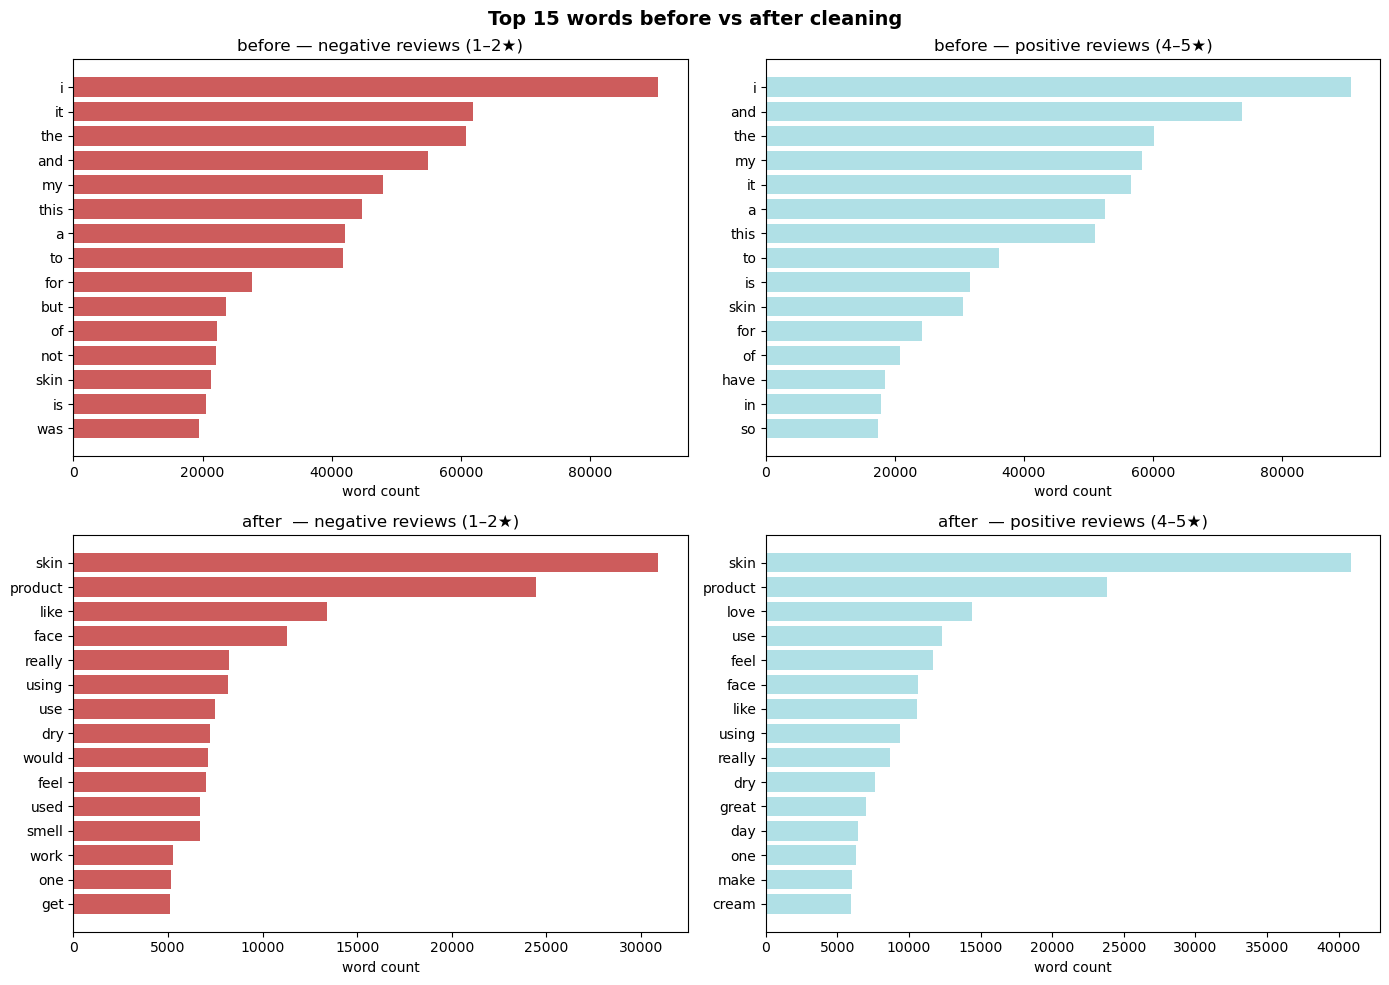

In [28]:
# we compare the top 15 most common words in negative and positive reviews before and after cleaning to show why stopword removal matters
# we use negative (0) and positive (2) reviews to make the contrast as clear as possible

# separating raw and cleaned text for negative and positive reviews
raw_negative = reviews_sample[reviews_sample['sentiment'] == 0]['review_text']
raw_positive = reviews_sample[reviews_sample['sentiment'] == 2]['review_text']
clean_negative = reviews_sample[reviews_sample['sentiment'] == 0]['clean_text']
clean_positive = reviews_sample[reviews_sample['sentiment'] == 2]['clean_text']

# counting the most common words in each group
def get_top_words(series, n=15):
    all_words = []
    for text in series:
        tokens = str(text).lower().split()
        tokens = [t for t in tokens if t.isalpha()]
        all_words.extend(tokens)
    return Counter(all_words).most_common(n)

# getting top words for each group
top_neg_raw   = get_top_words(raw_negative)
top_pos_raw   = get_top_words(raw_positive)
top_neg_clean = get_top_words(clean_negative)
top_pos_clean = get_top_words(clean_positive)

# plotting
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Top 15 words before vs after cleaning', fontsize=14, fontweight='bold')

def plot_words(ax, word_count_list, title, color):
    words, counts = zip(*word_count_list)
    ax.barh(words[::-1], counts[::-1], color=color)
    ax.set_title(title)
    ax.set_xlabel('word count')

plot_words(axes[0, 0], top_neg_raw,   'before — negative reviews (1–2★)', 'indianred')
plot_words(axes[0, 1], top_pos_raw,   'before — positive reviews (4–5★)', 'powderblue')
plot_words(axes[1, 0], top_neg_clean, 'after  — negative reviews (1–2★)', 'indianred')
plot_words(axes[1, 1], top_pos_clean, 'after  — positive reviews (4–5★)', 'powderblue')

plt.tight_layout()
plt.show()

# before cleaning: both charts look almost identical — dominated by "the", "and", "it"
# after cleaning: the words are clearly different between negative and positive reviews
# negative reviews contain words like "return", "disappointed", "waste"
# positive reviews contain words like "love", "great", "perfect"

### 4. Training baseline models 

Comparison of Naive Bayes and Logistic Regression

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("All libraries imported successfully")

All libraries imported successfully


##### 4.1 Train/test split

In [30]:
# we use 80% for training and 20% for testing
# stratify=y to make sure all three sentiment classes are represented proportionally in both the training and test sets!!

X = reviews_sample['clean_text']   # input: cleaned review text
y = reviews_sample['sentiment']    # target: 0 = negative, 1 = neutral, 2 = positive

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("training samples:", len(X_train))
print("test samples:    ", len(X_test))

training samples: 79999
test samples:     20000


##### Step 4.2 TF-IDF vectorization

- it converts our cleaned text into a matrix of numbers
  - words that appear often in one review but rarely across all reviews get a high score
  - common words that appear everywhere get a low score

In [31]:
# we use fit_transform on the training set which learns the vocabulary
# we use only transform on the test set which applies the learned vocabulary
# we never fit on the test set!

tfidf = TfidfVectorizer(
    max_features=10000,      # keeping the 10000 most important unigram/bigram features
    ngram_range=(1, 2)       # using both unigrams and bigrams
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print("shape of training matrix:", X_train_tfidf.shape)
print("shape of test matrix:    ", X_test_tfidf.shape)

shape of training matrix: (79999, 10000)
shape of test matrix:     (20000, 10000)


##### 4.3 Word clouds using the weights calculated by TF-IDF

Before we looked at the most common words that appear in each category, but now that we have done the vectorization, we can also look at which words are more useful for determining the class. 

From the graphs before, we noticed that common words after stopword removal are often still generic such as words like "product", "skin" and "use" appear in all reviews regardless of sentiment and so they are not very informative.

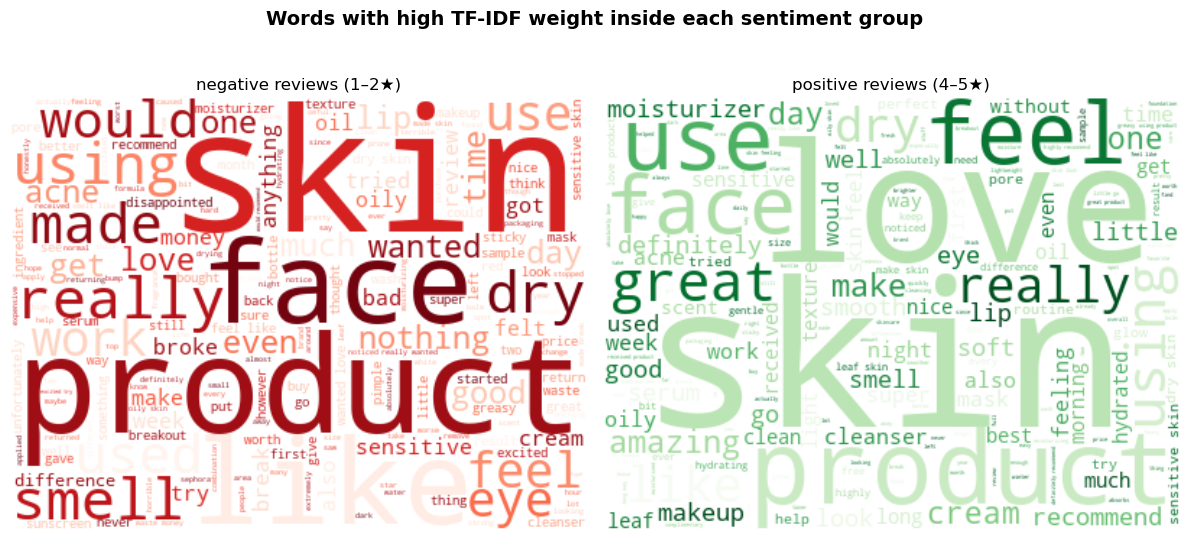

In [32]:
# this should highlights words that are distinctive to each sentiment class not just words that appear often overall

from wordcloud import WordCloud

# getting the feature names from already fitted TF-IDF vectorizer
feature_names = tfidf.get_feature_names_out()

# getting the average TF-IDF score per word for negative reviews (class 0)
# we only look at rows in the test/train data that belong to each class
negative_indices = [i for i, label in enumerate(y_train) if label == 0]
positive_indices = [i for i, label in enumerate(y_train) if label == 2]

# calculating the mean TF-IDF score for each word within each class
negative_scores = X_train_tfidf[negative_indices].mean(axis=0).A1
positive_scores = X_train_tfidf[positive_indices].mean(axis=0).A1

# creating dictionaries of word → score for each class
negative_word_scores = dict(zip(feature_names, negative_scores))
positive_word_scores = dict(zip(feature_names, positive_scores))

# plotting the word clouds
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle('Words with high TF-IDF weight inside each sentiment group', fontsize=14, fontweight='bold')

# negative word cloud
wordcloud_negative = WordCloud(
    width=400,
    height=300,
    background_color='white',
    colormap='Reds'
).generate_from_frequencies(negative_word_scores)  # using TF-IDF scores instead of raw counts

axes[0].imshow(wordcloud_negative, interpolation='bilinear')
axes[0].set_title('negative reviews (1–2★)', fontsize=12)
axes[0].axis('off')

# positive word cloud
wordcloud_positive = WordCloud(
    width=400,
    height=300,
    background_color='white',
    colormap='Greens'
).generate_from_frequencies(positive_word_scores)

axes[1].imshow(wordcloud_positive, interpolation='bilinear')
axes[1].set_title('positive reviews (4–5★)', fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

# negative cloud should highlight more words like "disappointed", "return", "waste" etc
# positive cloud should highlight more words like "love", "perfect", "amazing" etc

#####  4.3 Naive Bayes classification

In [33]:
# Naive Bayes is a simple probabilistic model that works well for text classification
# it calculates the probability of each class given the words in the review
# it is called "naive" because it assumes all words are independent of each other

#initializing the Naive Bayes model
nb_model = MultinomialNB()

#training the model on the training data
nb_model.fit(X_train_tfidf, y_train)

#using the trained model to predict sentiment on the test data
y_pred_nb = nb_model.predict(X_test_tfidf)

#evaluating the model
nb_accuracy  = accuracy_score(y_test, y_pred_nb)
nb_precision = precision_score(y_test, y_pred_nb, average='weighted')
nb_recall    = recall_score(y_test, y_pred_nb, average='weighted')
nb_f1        = f1_score(y_test, y_pred_nb, average='weighted')

#printing the results
print("Naive Bayes results:")
print("accuracy: ", round(nb_accuracy, 4))
print("precision:", round(nb_precision, 4))
print("recall:   ", round(nb_recall, 4))
print("f1-score: ", round(nb_f1, 4))

Naive Bayes results:
accuracy:  0.7156
precision: 0.7167
recall:    0.7156
f1-score:  0.7161


##### 4.4 Looking at what Naive Bayes actually learned

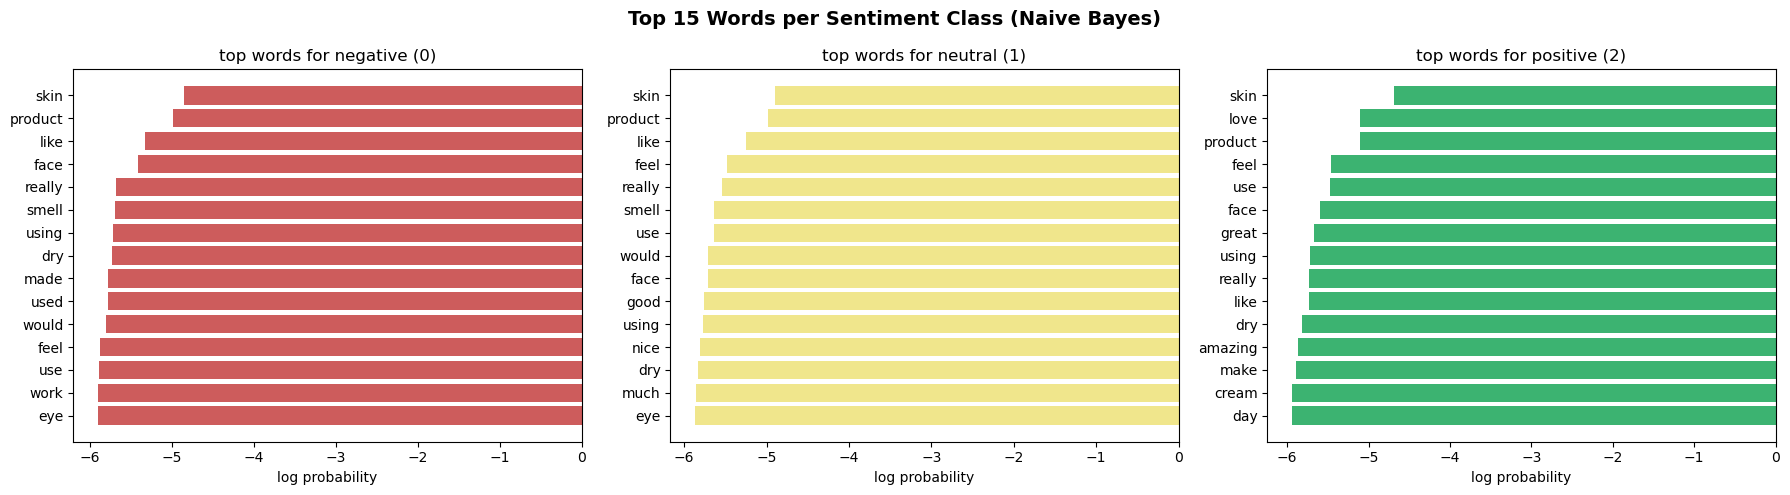

In [34]:
# we can look inside the Naive Bayes model to see which words
# it associates most strongly with each sentiment class
# this helps us understand if the model is learning meaningful patterns

feature_names = tfidf.get_feature_names_out()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Top 15 Words per Sentiment Class (Naive Bayes)', fontsize=14, fontweight='bold')

class_names = ['negative (0)', 'neutral (1)', 'positive (2)']
colors = ['indianred', 'khaki', 'mediumseagreen']

for i in range(3):
    
    #getting the log probabilities for this class vs all others
    log_probs = nb_model.feature_log_prob_[i]
    
    #finding the top 15 words with the highest log probability for this class
    top_indices = log_probs.argsort()[-15:]
    top_words   = [feature_names[j] for j in top_indices]
    top_scores  = [log_probs[j] for j in top_indices]
    
    axes[i].barh(top_words, top_scores, color=colors[i])
    axes[i].set_title(f'top words for {class_names[i]}')
    axes[i].set_xlabel('log probability')

plt.tight_layout()
plt.show()

This plot shows the most common/high-probability words per class, but they are for a large part very similar, because every review contains words like skin, product, feel, like etc, which makes the graph less informative and interesting. So now we'll try to create the same visual but with words that are more strongly associated with one class compared with the other classes.


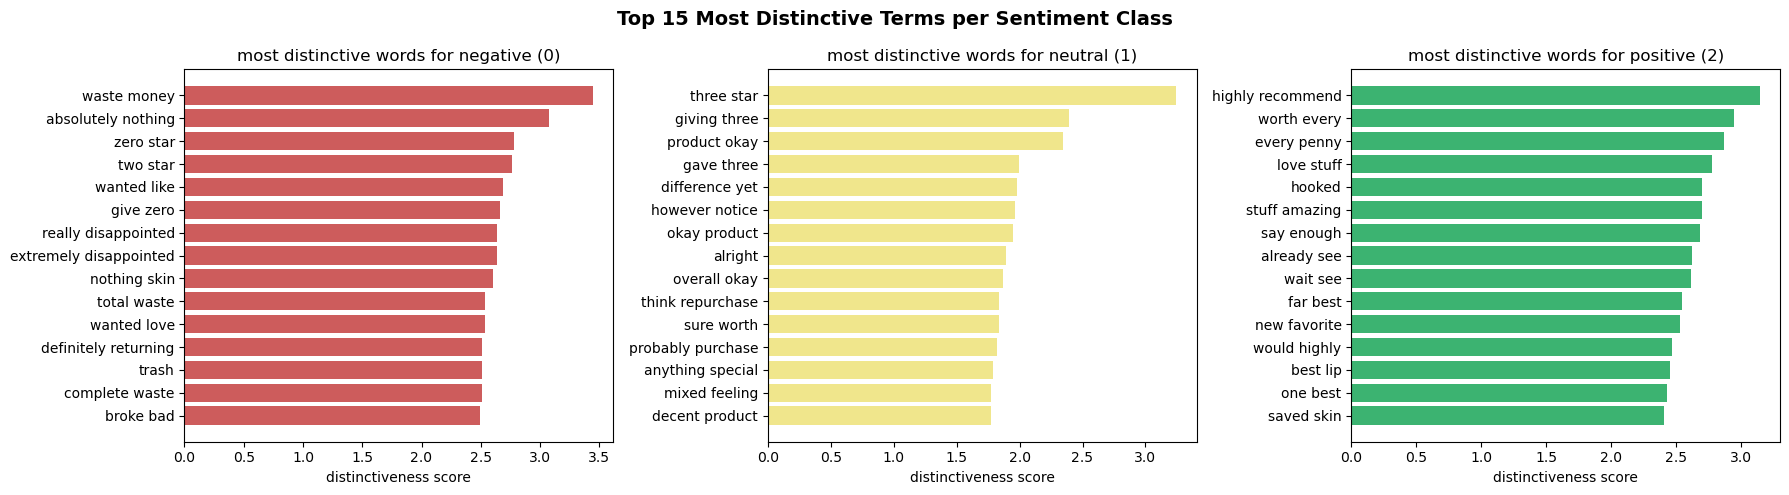

In [35]:
# More distinctive words per sentiment class - Naive Bayes

feature_names = tfidf.get_feature_names_out()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

fig.suptitle(
    'Top 15 Most Distinctive Terms per Sentiment Class',
    fontsize=14,
    fontweight='bold'
)

class_names = ['negative (0)', 'neutral (1)', 'positive (2)']
colors = ['indianred', 'khaki', 'mediumseagreen']

for i in range(3):
    
    # log probabilities for the current class
    class_log_probs = nb_model.feature_log_prob_[i]
    
    # log probabilities for the other two classes
    other_class_log_probs = np.delete(nb_model.feature_log_prob_, i, axis=0)
    
    # average log probability of each word in the other classes
    other_average_log_probs = other_class_log_probs.mean(axis=0)
    
    # distinctive score:
    # high score = word is more associated with this class than the others
    distinctive_scores = class_log_probs - other_average_log_probs
    
    # getting the top 15 most distinctive words
    top_indices = distinctive_scores.argsort()[-15:]
    top_words = [feature_names[j] for j in top_indices]
    top_scores = [distinctive_scores[j] for j in top_indices]
    
    # plotting
    axes[i].barh(top_words, top_scores, color=colors[i])
    axes[i].set_title(f'most distinctive words for {class_names[i]}')
    axes[i].set_xlabel('distinctiveness score')

plt.tight_layout()
plt.show()

##### 4.5 Logistic Regression classification

In [36]:
# Logistic Regression is a slightly more powerful model than Naive Bayes
# instead of calculating probabilities, it learns a set of weights for each word
# words that are strongly associated with a class get high positive weights
# words that are strongly against a class get high negative weights

#initializing the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)  # max_iter=1000 gives the model enough iterations to converge

#training the model on the TF-IDF training data
lr_model.fit(X_train_tfidf, y_train)

#making predictions on the test data
y_pred_lr = lr_model.predict(X_test_tfidf)

#evaluating the model
lr_accuracy  = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, average='weighted')
lr_recall    = recall_score(y_test, y_pred_lr, average='weighted')
lr_f1        = f1_score(y_test, y_pred_lr, average='weighted')

#printing the results
print("Logistic Regression results:")
print("accuracy: ", round(lr_accuracy, 4))
print("precision:", round(lr_precision, 4))
print("recall:   ", round(lr_recall, 4))
print("f1-score: ", round(lr_f1, 4))

Logistic Regression results:
accuracy:  0.7426
precision: 0.7419
recall:    0.7426
f1-score:  0.7422


##### 4.6 Confusion matrices for both models

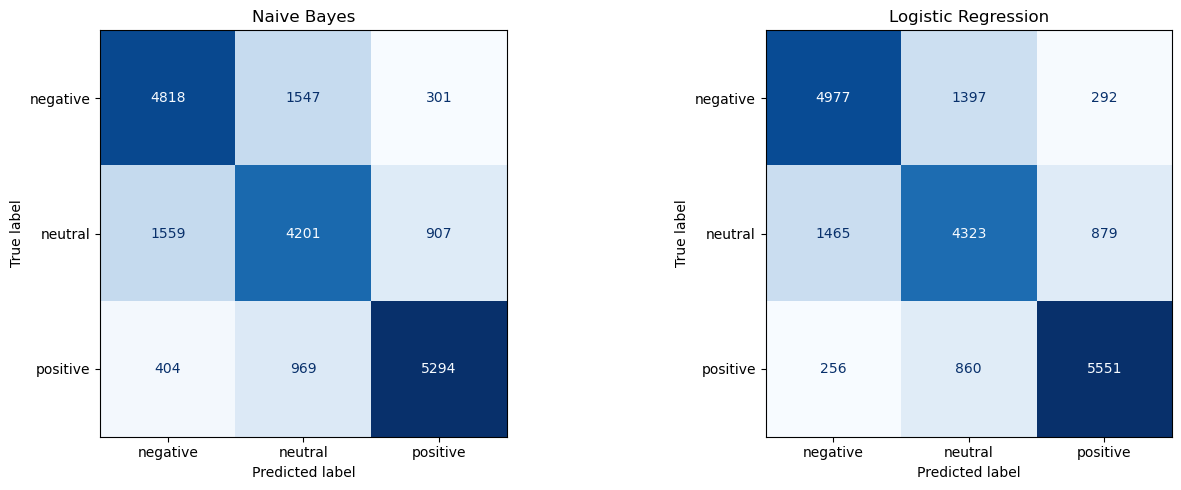

In [37]:
# the diagonal shows correct predictions, off-diagonal cells show where the model confused one class for another

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class_labels = ['negative', 'neutral', 'positive']

#naive bayes confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)
ConfusionMatrixDisplay(cm_nb, display_labels=class_labels).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Naive Bayes')

#logistic regression confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm_lr, display_labels=class_labels).plot(ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Logistic Regression')

plt.tight_layout()
plt.show()

##### 4.7 Comparing model performance

In [38]:
# finally we put both models results into one clean table for easy comparison

results = pd.DataFrame({
    'model':     ['Naive Bayes', 'Logistic Regression'],
    'accuracy':  [round(nb_accuracy, 4),  round(lr_accuracy, 4)],
    'precision': [round(nb_precision, 4), round(lr_precision, 4)],
    'recall':    [round(nb_recall, 4),    round(lr_recall, 4)],
    'f1-score':  [round(nb_f1, 4),        round(lr_f1, 4)]
})

print(results.to_string(index=False))

              model  accuracy  precision  recall  f1-score
        Naive Bayes    0.7156     0.7167  0.7156    0.7161
Logistic Regression    0.7426     0.7419  0.7426    0.7422


##### Commented before new sampling technique! (now much better) These accuracy scores look suspiciously high, so we will further check performance. It's likely that the neutral class (1) is being predicted very poorly because the model is probably just defaulting to positive most of the time 

In [39]:
# checking how often each class is predicted

print("Naive Bayes prediction distribution:")
print(pd.Series(y_pred_nb).value_counts().sort_index())

print("\nActual distribution in test set:")
print(y_test.value_counts().sort_index())

Naive Bayes prediction distribution:
0    6781
1    6717
2    6502
dtype: int64

Actual distribution in test set:
0    6666
1    6667
2    6667
Name: sentiment, dtype: int64


##### Interpreting model performance:

- After applying random undersampling to balance the three sentiment classes, accuracy dropped from ~87% to ~70% but overall they still give a better picture of model performance
- The confusion matrices now show that models are actually attempting to predict all three classes, rather than defaulting to positive
- The neutral class remains the hardest to classify for both models, which makes sense because neutral reviews often contain mixed language that simple word frequency models cannot interpret correctly
- This limitation motivates the use of more sophisticated models like BERT, which can understand context and nuance rather than just counting words

### 5. Fitting MLP Classfier - Neural Network

In [40]:
# a neural network learns patterns by passing data through multiple layers of "neurons"
# each layer transforms the input a little more, allowing the model to learnmore complex patterns than Naive Bayes or Logistic Regression can
 
# we use the same TF-IDF as before

from sklearn.neural_network import MLPClassifier

print("MLPClassifier imported successfully")

MLPClassifier imported successfully


In [41]:
# we initialize the MLP with two hidden layers of 100 neurons each
# hidden_layer_sizes=(100, 100) means two layers, 100 neurons in each
# max_iter=50 gives the model up to 50 passes through the training data
# verbose=True prints the loss after each pass so we can see it learning

mlp_model = MLPClassifier(
    hidden_layer_sizes=(100, 100),  # two hidden layers with 100 neurons each
    max_iter=50,                    # maximum number of training passes
    random_state=42,                # for reproducibility
    verbose=True                    # prints training progress
)

mlp_model.fit(X_train_tfidf, y_train)

print("\nDone training!")

Iteration 1, loss = 0.66955757
Iteration 2, loss = 0.52106505
Iteration 3, loss = 0.46611953
Iteration 4, loss = 0.39169617
Iteration 5, loss = 0.28037241
Iteration 6, loss = 0.15600875
Iteration 7, loss = 0.06629785
Iteration 8, loss = 0.02346161
Iteration 9, loss = 0.00868185
Iteration 10, loss = 0.00472252
Iteration 11, loss = 0.00316335
Iteration 12, loss = 0.00300450
Iteration 13, loss = 0.00245731
Iteration 14, loss = 0.00263465
Iteration 15, loss = 0.00226734
Iteration 16, loss = 0.00245208
Iteration 17, loss = 0.00284312
Iteration 18, loss = 0.03928257
Iteration 19, loss = 0.04033843
Iteration 20, loss = 0.00928084
Iteration 21, loss = 0.00338679
Iteration 22, loss = 0.00263231
Iteration 23, loss = 0.00243921
Iteration 24, loss = 0.00240338
Iteration 25, loss = 0.00232561
Iteration 26, loss = 0.00236698
Training loss did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.

Done training!


In [42]:
#using the trained model to predict sentiment on the test data
y_pred_mlp = mlp_model.predict(X_test_tfidf)

#evaluating the model using the same metrics as before
mlp_accuracy = accuracy_score(y_test, y_pred_mlp)
mlp_precision = precision_score(y_test, y_pred_mlp, average='weighted')
mlp_recall = recall_score(y_test, y_pred_mlp, average='weighted')
mlp_f1 = f1_score(y_test, y_pred_mlp, average='weighted')

#printing the results
print("MLP Classifier results:")
print("accuracy: ", round(mlp_accuracy, 4))
print("precision:", round(mlp_precision, 4))
print("recall:   ", round(mlp_recall, 4))
print("f1-score: ", round(mlp_f1, 4))

MLP Classifier results:
accuracy:  0.7126
precision: 0.7119
recall:    0.7126
f1-score:  0.7122


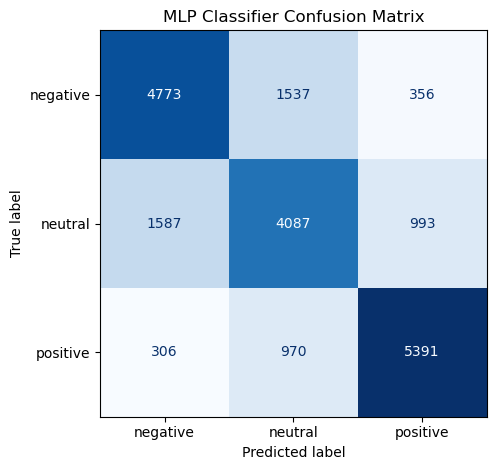

In [43]:
#looking at where the model makes mistakes
class_labels = ['negative', 'neutral', 'positive']

cm_mlp = confusion_matrix(y_test, y_pred_mlp)
ConfusionMatrixDisplay(cm_mlp, display_labels=class_labels).plot(colorbar=False, cmap='Blues')
plt.title('MLP Classifier Confusion Matrix')
plt.tight_layout()
plt.show()

In [44]:
# we add the MLP results to our comparison table from step 4
# this lets us track how performance improves as models get more complex

results = pd.DataFrame({
    'model':     ['Naive Bayes', 'Logistic Regression', 'MLP Classifier'],
    'accuracy':  [round(nb_accuracy, 4),  round(lr_accuracy, 4),  round(mlp_accuracy, 4)],
    'precision': [round(nb_precision, 4), round(lr_precision, 4), round(mlp_precision, 4)],
    'recall':    [round(nb_recall, 4),    round(lr_recall, 4),    round(mlp_recall, 4)],
    'f1-score':  [round(nb_f1, 4),        round(lr_f1, 4),        round(mlp_f1, 4)]
})

print(results.to_string(index=False))

              model  accuracy  precision  recall  f1-score
        Naive Bayes    0.7156     0.7167  0.7156    0.7161
Logistic Regression    0.7426     0.7419  0.7426    0.7422
     MLP Classifier    0.7126     0.7119  0.7126    0.7122


##### MLP is not dramatically better than Naive Bayes on minority classes because it is still heavily biased towards predicting positive. We will try eliminating the class imbalance later. 

### 6. Word embedding with Word2Vec - redoing Logistic Regression with dense vectors

Now we will try using Word2Vec as the text representation method. The idea is that words used in similar contexts get similar vectors. So words like moisturizer, cream etc should end up close together in vector space, which could be a good alternative for TF-IDF (TF-IDF treats words as separate features, while Word2Vec captures semantic similarity). So basically we are moving from sparse to dense vector representations.

In [45]:
# we use Gensim to train a Word2Vec model on our review corpus (same as in exercise class)

from gensim.models import Word2Vec
import numpy as np

print("libraries imported successfully")

libraries imported successfully


##### 6.1 Splitting the text into individual words and storing as a list

In [46]:
# Word2Vec needs the text as a list of lists
# so basically each review becomes a list of individual words (vs TF-IDF needed a single string)

# we tokenize the cleaned reviews by splitting on whitespace (but here the text is already cleaned and lowercased from step 3)

tokenized_reviews = [text.split() for text in reviews_sample['clean_text']]

#checking the result
print(f"Number of tokenized reviews: {len(tokenized_reviews):,}")
print(f"\nExample (first review):")
print(tokenized_reviews[0][:15])  #showing just the first 15 words

Number of tokenized reviews: 99,999

Example (first review):
['received', 'influenster', 'part', 'campaign', 'thrilled', 'normally', 'love', 'clinique', 'product', 'used', 'week', 'wish', 'worked', 'better', 'cream']


##### 6.2 Training Word2Vec model on our review corpus using the Skip-Gram method

In [47]:
# as covered in lecture 8 — for each word, it learns to predict nearby words

# key parameters:
# vector_size = 100  → each word gets a vector of 100 numbers
# window = 5         → the model looks 5 words to the left and right of each word
# min_count = 2      → ignores words that appear fewer than 2 times (this should help remove many typos and random words), will make our vocabulary smaller also
# sg = 1             → sg=1 means Skip-Gram (sg=0 would be CBOW)
# workers = 4        → uses 4 CPU threads to speed up training

w2v_model = Word2Vec(
    sentences=tokenized_reviews,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    seed=42
)

print(f"Word2Vec model trained successfully!")
print(f"vocabulary size: {len(w2v_model.wv):,} words")

Word2Vec model trained successfully!
vocabulary size: 14,438 words


##### 6.3 Looking at what the Word2Vec learned

In [48]:
# before using Word2Vec for classification, we'll check if it learned meaningful representations from our skincare reviews
# for this we'll just pick a couple of random words

print("Most similar words to 'moisturizer':")
print(w2v_model.wv.most_similar('moisturizer', topn=5))

print("\nMost similar words to 'love':")
print(w2v_model.wv.most_similar('love', topn=5))

print("\nMost similar words to 'disappointed':")
print(w2v_model.wv.most_similar('disappointed', topn=5))

Most similar words to 'moisturizer':
[('moisturiser', 0.8368726372718811), ('moisterizer', 0.8259552717208862), ('cream', 0.755752444267273), ('serum', 0.7380694150924683), ('moisturizing', 0.6901530027389526)]

Most similar words to 'love':
[('obsessed', 0.7832623720169067), ('amazing', 0.7787196040153503), ('loveeee', 0.7693067193031311), ('awesome', 0.7581392526626587), ('loved', 0.7551144361495972)]

Most similar words to 'disappointed':
[('disappointing', 0.8209066390991211), ('bummed', 0.7902593016624451), ('dissatisfied', 0.7287952303886414), ('upset', 0.7196714878082275), ('sad', 0.7193042635917664)]


##### 6.4 Converting reviews to vectors

Basically we're averaging them like this: average(love vector + this vector + moisturizer vector), and creating a review vector of 100 numbers

In [49]:
def review_to_vector(text, model, vector_size=100):

    #splitting the review into individual words
    words = text.split()

    #getting the vector for each word that exists in our vocabulary
    word_vectors = []
    for word in words:
        if word in model.wv:
            word_vectors.append(model.wv[word])

    #if none of the words are in the vocabulary, return a zero vector
    if len(word_vectors) == 0:
        return np.zeros(vector_size)

    #averaging all the word vectors to get one vector for the whole review
    return np.mean(word_vectors, axis=0)

#applying the function to every review in our sample
print("Converting reviews to Word2Vec vectors...")

X_w2v = np.array([
    review_to_vector(text, w2v_model)
    for text in reviews_sample['clean_text']
])

print(f"Done! shape of feature matrix: {X_w2v.shape}")

#should be (99999, 100) so 99999, each with a 100-dimensional vector (works)

Converting reviews to Word2Vec vectors...
Done! shape of feature matrix: (99999, 100)


##### 6.5 Train/test split and classification

In [50]:
# we use the same target variable as before as in sentiments: 0, 1, 2 and the same 80/20 split so results are comparable

y_w2v = reviews_sample['sentiment']

X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v = train_test_split(
    X_w2v, y_w2v, test_size=0.2, random_state=42, stratify=y_w2v
)

print(f"training samples: {len(X_train_w2v):,}")
print(f"test samples:     {len(X_test_w2v):,}")

# training a Logistic Regression on the Word2Vec features
# we use the same classifier as before so the comparison is fair
# the only thing that changes is the input features (Word2Vec vs TF-IDF)

w2v_lr_model = LogisticRegression(max_iter=1000, random_state=42)
w2v_lr_model.fit(X_train_w2v, y_train_w2v)

# making predictions
y_pred_w2v = w2v_lr_model.predict(X_test_w2v)

# evaluating the model
w2v_accuracy  = accuracy_score(y_test_w2v, y_pred_w2v)
w2v_precision = precision_score(y_test_w2v, y_pred_w2v, average='weighted')
w2v_recall    = recall_score(y_test_w2v, y_pred_w2v, average='weighted')
w2v_f1        = f1_score(y_test_w2v, y_pred_w2v, average='weighted')

print("\nWord2Vec + Logistic Regression results:")
print("accuracy: ", round(w2v_accuracy, 4))
print("precision:", round(w2v_precision, 4))
print("recall:   ", round(w2v_recall, 4))
print("f1-score: ", round(w2v_f1, 4))

training samples: 79,999
test samples:     20,000

Word2Vec + Logistic Regression results:
accuracy:  0.6612
precision: 0.6606
recall:    0.6612
f1-score:  0.6608


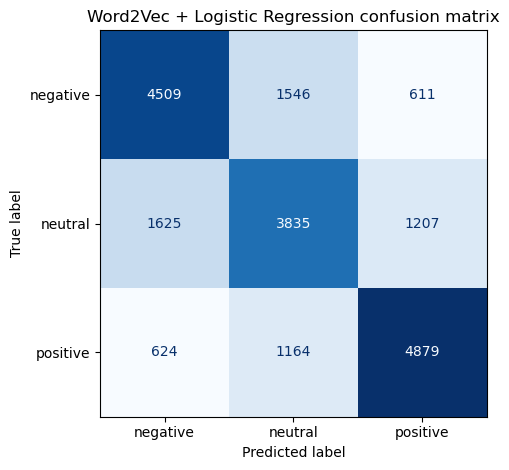

In [51]:
class_labels = ['negative', 'neutral', 'positive']

cm_w2v = confusion_matrix(y_test_w2v, y_pred_w2v)
ConfusionMatrixDisplay(cm_w2v, display_labels=class_labels).plot(
    colorbar=False, cmap='Blues'
)

plt.title('Word2Vec + Logistic Regression confusion matrix')
plt.tight_layout()
plt.show()

##### Some insights:

Turns out that Logistic Regression with TF-IDF performs better than Logistic Regression with Word2Vec. Both models are strongest at predicting positive reviews (because it's the majority class), but both do badl with with negative and neutral reviews. The Word2Vec model is even more biased toward predicting the positive class. This might be because in skincare reviews customers often use very specific complaint words, such as irritation, breakouts, dryness, burning etc and TF-IDF is better in representing that. 

In [52]:
# adding Word2Vec results to our running comparison table

results = pd.DataFrame({
    'model':     ['Naive Bayes', 'Logistic Regression', 'MLP Classifier', 'Word2Vec + LR'],
    'accuracy':  [round(nb_accuracy, 4),  round(lr_accuracy, 4),  round(mlp_accuracy, 4),  round(w2v_accuracy, 4)],
    'precision': [round(nb_precision, 4), round(lr_precision, 4), round(mlp_precision, 4), round(w2v_precision, 4)],
    'recall':    [round(nb_recall, 4),    round(lr_recall, 4),    round(mlp_recall, 4),    round(w2v_recall, 4)],
    'f1-score':  [round(nb_f1, 4),        round(lr_f1, 4),        round(mlp_f1, 4),        round(w2v_f1, 4)]
})

print(results.to_string(index=False))

              model  accuracy  precision  recall  f1-score
        Naive Bayes    0.7156     0.7167  0.7156    0.7161
Logistic Regression    0.7426     0.7419  0.7426    0.7422
     MLP Classifier    0.7126     0.7119  0.7126    0.7122
      Word2Vec + LR    0.6612     0.6606  0.6612    0.6608


##### The fact that all four models scored around 66-72% F1 is actually a really interesting because it suggests there is a ceiling for what simple word-based approaches can achieve on this task. All the models look at which words appear in a review, with no understanding of context, so theoretically BERT should outperform them by quite a lot. 

### 7. Training transformer-based BERT models (ran in Colab)

- Transformers use attention mechanism to allow word representations to
be enriched by context


In [53]:
# saving our preprocessed sample so we can upload it to Colab
reviews_sample[['review_text', 'clean_text', 'bert_text', 'rating', 'sentiment']].to_csv('reviews_sample_balanced.csv', index=False)
print("Saved!")

Saved!


#### 7.1 TinyBERT

In [54]:
# in the other doc from colab

#### 7.2 DistilBERT

In [55]:
# in the other doc from colab

### 8. Prompting, both Zero - shot and Few - shot

In [56]:
# storing the API key as a variable

import openai

print(f"openai version: {openai.__version__}")

# reloading the preprocessed sample
reviews_sample = pd.read_csv('reviews_sample_balanced.csv').dropna(subset=['bert_text', 'sentiment'])
reviews_sample['sentiment'] = reviews_sample['sentiment'].astype(int)

print(f"loaded {len(reviews_sample):,} reviews")

openai version: 2.33.0
loaded 99,999 reviews


In [57]:
from openai import OpenAI

# testing the API key with a simple request
import os
# the key is read from an environment variable, never hard-code it
client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])

# checking which models are available with this API key (because it wasnt working with 4 or 3.5 turbo when I tried it before)
models = client.models.list()

for model in models.data:
    print(model.id)

text-embedding-3-large
o3
gpt-5-mini
gpt-5-nano
gpt-5.2


In [58]:
# creating a test sample for GPT

# going to try only classifying 150 reviews with GPT 

gpt_sample = reviews_sample.groupby('sentiment', group_keys=False).apply(
    lambda x: x.sample(50, random_state=42)
).reset_index(drop=True)

print(f"GPT sample size: {len(gpt_sample)}")
print(gpt_sample['sentiment'].value_counts().sort_index())

GPT sample size: 150
0    50
1    50
2    50
Name: sentiment, dtype: int64


#### 8.1 Zero-shot classification

- zero-shot means we give GPT NO examples
- we just tell it what to do and it figures it out

In [59]:
# this is our prompt 
import time

zero_shot_prompt = """You are classifying skincare product reviews by sentiment.Read the review and decide if it is negative, neutral, or positive.
negative = 1 or 2 stars, meaning the customer is unhappy
neutral = 3 stars, meaning the customer has mixed feelings
positive = 4 or 5 stars, meaning the customer is happy
Only answer with one word: negative, neutral, or positive."""

zero_shot_preds = []

for i, row in gpt_sample.iterrows():

    # sending the review to GPT with simple instructions
    response = client.chat.completions.create(
        model="gpt-5-mini",
        messages=[
            {
                "role": "user",
                "content": f"Classify this skincare review as negative, neutral, or positive. Reply with one word only.\n\nReview: {row['review_text']}"
            }
        ]
    )

    # reading the response
    answer = response.choices[0].message.content.strip().lower()

    # converting to numeric label
    if 'positive' in answer:
        zero_shot_preds.append(2)
    elif 'neutral' in answer:
        zero_shot_preds.append(1)
    elif 'negative' in answer:
        zero_shot_preds.append(0)
    else:
        zero_shot_preds.append(-1)

    time.sleep(0.3)

print(f"total predictions: {len(zero_shot_preds)}")
print(f"unexpected responses: {zero_shot_preds.count(-1)}") #ones that dont match the rules of answering with 1 word

total predictions: 150
unexpected responses: 0


#### 8.2 Few-shot classification

In [60]:
few_shot_preds = []

for i, row in gpt_sample.iterrows():

    # sending the review to GPT with examples included in the message
    response = client.chat.completions.create(
        model="gpt-5-mini",
        messages=[
            {
                "role": "user",
                "content": f"""Classify skincare reviews as negative, neutral, or positive. Reply with one word only.

Review: "This broke me out and irritated my skin. Returning it."
Sentiment: negative

Review: "It is okay, nothing special. Does what it claims but nothing more."
Sentiment: neutral

Review: "Absolutely love this! My skin has never felt so soft and hydrated."
Sentiment: positive

Now classify this review:
Review: {row['review_text']}
Sentiment:"""
            }
        ]
    )

    answer = response.choices[0].message.content.strip().lower()

    if 'positive' in answer:
        few_shot_preds.append(2)
    elif 'neutral' in answer:
        few_shot_preds.append(1)
    elif 'negative' in answer:
        few_shot_preds.append(0)
    else:
        few_shot_preds.append(-1)

    time.sleep(0.3)

print(f"total predictions: {len(few_shot_preds)}")
print(f"unexpected responses: {few_shot_preds.count(-1)}")

total predictions: 150
unexpected responses: 0


In [61]:
# evaluating both GPT approaches

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

true_labels = gpt_sample['sentiment'].tolist()

# zero-shot metrics
zs_accuracy = accuracy_score(true_labels, zero_shot_preds)
zs_f1 = f1_score(true_labels, zero_shot_preds, average='weighted')
zs_precision = precision_score(true_labels, zero_shot_preds, average='weighted')
zs_recall = recall_score(true_labels, zero_shot_preds, average='weighted')

# few-shot metrics
fs_accuracy  = accuracy_score(true_labels, few_shot_preds)
fs_f1 = f1_score(true_labels, few_shot_preds, average='weighted')
fs_precision = precision_score(true_labels, few_shot_preds, average='weighted')
fs_recall = recall_score(true_labels, few_shot_preds, average='weighted')

print("Results")
print(f"\nzero-shot (no examples):")
print(f"  accuracy:  {round(zs_accuracy, 4)}")
print(f"  precision: {round(zs_precision, 4)}")
print(f"  recall:    {round(zs_recall, 4)}")
print(f"  f1-score:  {round(zs_f1, 4)}")

print(f"\nfew-shot (6 examples):")
print(f"  accuracy:  {round(fs_accuracy, 4)}")
print(f"  precision: {round(fs_precision, 4)}")
print(f"  recall:    {round(fs_recall, 4)}")
print(f"  f1-score:  {round(fs_f1, 4)}")

Results

zero-shot (no examples):
  accuracy:  0.68
  precision: 0.7031
  recall:    0.68
  f1-score:  0.5961

few-shot (6 examples):
  accuracy:  0.7
  precision: 0.7389
  recall:    0.7
  f1-score:  0.632


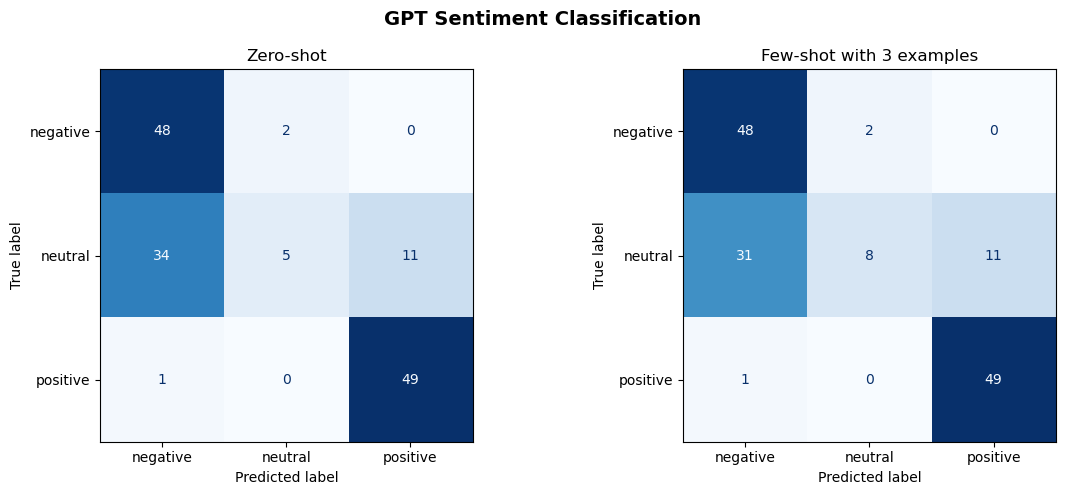

In [62]:
# confusion matrices
class_labels = ['negative', 'neutral', 'positive']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('GPT Sentiment Classification', fontsize=14, fontweight='bold')

cm_zero = confusion_matrix(true_labels, zero_shot_preds)
ConfusionMatrixDisplay(cm_zero, display_labels=class_labels).plot(
    ax=axes[0], colorbar=False, cmap='Blues'
)
axes[0].set_title('Zero-shot')

cm_few = confusion_matrix(true_labels, few_shot_preds)
ConfusionMatrixDisplay(cm_few, display_labels=class_labels).plot(
    ax=axes[1], colorbar=False, cmap='Blues'
)
axes[1].set_title('Few-shot with 3 examples')

plt.tight_layout()
plt.show()

#### 8.3 chain-of-thought prompting

In [79]:

# chain-of-thought prompting asks the model to reason throughthe review before giving a final answer
# this is different from zero-shot and few-shot because the model is explicitly instructed to think step by step before classifying
# we are interested in whether this improves performance on the neutral class, where GPT struggled most in the previous experiments

print("running chain-of-thought prompting...")

cot_preds = []

for i, row in gpt_sample.iterrows():

    response = client.chat.completions.create(
        model="gpt-5-mini",
        messages=[
            {
                "role": "user",
                "content": f"""You are classifying skincare product reviews into three sentiment categories: negative, neutral, or positive.

First, briefly identify whether the review contains mostly positive language, mostly negative language, or a mix of both positive and negative language.
Then give your final classification as exactly one word on a new line: negative, neutral, or positive.

Important: if the review contains both positive and negative language, or expresses mixed feelings, classify it as neutral.

Review: {row['review_text']}"""
            }
        ]
    )

    # reading the full response
    full_answer = response.choices[0].message.content.strip().lower()

    # the model is asked to reason first and then give a one word answer
    # we extract the last word of the response as the final classification
    # since chain of thought produces longer responses
    last_word = full_answer.split()[-1].strip('.,!?')

    if 'positive' in last_word:
        cot_preds.append(2)
    elif 'neutral' in last_word:
        cot_preds.append(1)
    elif 'negative' in last_word:
        cot_preds.append(0)
    else:
        # if the last word is not a valid label, search the full response
        if 'positive' in full_answer:
            cot_preds.append(2)
        elif 'neutral' in full_answer:
            cot_preds.append(1)
        elif 'negative' in full_answer:
            cot_preds.append(0)
        else:
            cot_preds.append(-1)

    time.sleep(0.3)

print(f"done! total predictions: {len(cot_preds)}")
print(f"unexpected responses: {cot_preds.count(-1)}")

running chain-of-thought prompting...
done! total predictions: 150
unexpected responses: 0


In [80]:
# evaluating chain-of-thought

# computing metrics the same way as before
cot_accuracy  = accuracy_score(true_labels, cot_preds)
cot_precision = precision_score(true_labels, cot_preds, average='weighted')
cot_recall    = recall_score(true_labels, cot_preds, average='weighted')
cot_f1        = f1_score(true_labels, cot_preds, average='weighted')

print("=== chain-of-thought results ===")
print(f"accuracy:  {round(cot_accuracy, 4)}")
print(f"precision: {round(cot_precision, 4)}")
print(f"recall:    {round(cot_recall, 4)}")
print(f"f1-score:  {round(cot_f1, 4)}")

# comparing all three GPT strategies side by side
gpt_results = pd.DataFrame({
    'strategy':  ['zero-shot', 'few-shot', 'chain-of-thought'],
    'accuracy':  [round(zs_accuracy, 4),  round(fs_accuracy, 4),  round(cot_accuracy, 4)],
    'precision': [round(zs_precision, 4), round(fs_precision, 4), round(cot_precision, 4)],
    'recall':    [round(zs_recall, 4),    round(fs_recall, 4),    round(cot_recall, 4)],
    'f1-score':  [round(zs_f1, 4),        round(fs_f1, 4),        round(cot_f1, 4)]
})

print("\n=== GPT prompting strategies comparison ===")
print(gpt_results.to_string(index=False))

=== chain-of-thought results ===
accuracy:  0.74
precision: 0.8026
recall:    0.74
f1-score:  0.7406

=== GPT prompting strategies comparison ===
        strategy  accuracy  precision  recall  f1-score
       zero-shot      0.68     0.7031    0.68    0.5961
        few-shot      0.70     0.7389    0.70    0.6320
chain-of-thought      0.74     0.8026    0.74    0.7406


##### Interpretations: 

- For negative reviews, both zero-shot and few-shot got 48/50 correct (96%)
- For positive reviews, both got 49/50 correct (98%)
- For neutral reviews, 
    - Zero-shot got only 5/50 correct (10%) and mostly predicted them as negative (34!)
    - Few-shot did a little bit better, 9/50 correct (18%) but still mostly predicted as negative (30)

From all these models, it's clear that neutral is the hardest class to predict. And GPT specifically seems to interpret mixed or mediocre reviews as negative rather than neutral. 

### 9. Creating a product recommendation system

We have built models that classify sentiment in reviews and now we'll attempt to build something practical with those models and make a a simple product recommender system.

The idea is that a user types what they are looking for in plain english such as "moisturizer for oily skin". The recommendation system finds the most relevant products from the dataset by comparing the user query to product reviews using cosine similarity, which measures how similar two vectors are. The system then finds the most relevant products from the sephora dataset and returns them ranked by relevance.

The recommender is built on two techniques we have used throughout this course:

 1. TF-IDF vectorization - combining all reviews for each product into one large text summary and then converting these summaries into TFIDF vectors. The user query is also converted into a TF-IDF vector using the same vocabulary.

2. cosine similarity - once both the query and the products are represented as vectors, we use cosine similarity to measure how similar the query vector is to each product vector. A score of 1 means identical, 0 means completely different. So products whose reviews use similar language to the query get a high similarity score and are ranked at the top.


We will also attach the sentiment scores from our classification models to each recommended product — so the user can also see how positively other customers have reviewed them. Ths uses information retrieval (finding relevant products) and sentiment analysis (evaluating product quality). This could also be refined and expanded later to create a smarter search feature for Sephora. 

In [63]:
from sklearn.metrics.pairwise import cosine_similarity

print("libraries imported successfully")

libraries imported successfully


##### 9.1 Preparing product summaries, have to merge the two datasets 

In [64]:
# for each product we create one combined text summary by joining all its reviews together into one string
# this gives us a long description of what customers say about each product

# we work with the full reviews dataframe (not just the sample like before) so we have as many products as possible

# first merging reviews with product info to get product names and prices
# we only keep the columns we need
product_reviews = reviews[['product_id', 'product_name', 'brand_name', 
                            'price_usd', 'review_text']].dropna()

# grouping all reviews by product and joining them into one text per product
product_summaries = product_reviews.groupby(
    ['product_id', 'product_name', 'brand_name', 'price_usd']
)['review_text'].apply(lambda x: ' '.join(x)).reset_index()

product_summaries.columns = ['product_id', 'product_name', 'brand_name', 'price_usd', 'all_reviews']

print(f"Number of products with reviews: {len(product_summaries):,}")
print("\nFirst 3 products:")
product_summaries[['product_name', 'brand_name', 'price_usd']].head(5)

Number of products with reviews: 2,351

First 3 products:


,product_name,brand_name,price_usd
0,Renewing Eye Cream,Murad,89.0
1,Goodbye Acne Max Complexion Correction Pads,Peter Thomas Roth,48.0
2,Grape Water Moisturizing Face Mist,Caudalie,12.0
3,Clarifying Lotion 1,CLINIQUE,20.0
4,7 Day Face Scrub Cream Rinse-Off Formula,CLINIQUE,26.0


##### 9.2 Adding sentiment scores to each product

In [65]:
# calculating % positive reviews per product
sentiment_by_product = reviews.groupby('product_id')['sentiment'].apply(
    lambda x: round((x == 2).sum() / len(x) * 100, 1)
).reset_index()

sentiment_by_product.columns = ['product_id', 'positive_pct']

# merging sentiment scores into our product summaries
product_summaries = product_summaries.merge(
    sentiment_by_product, on='product_id', how='left'
)

print(f"\nProducts with sentiment scores: {product_summaries['positive_pct'].notna().sum():,}")
print("\nExample:")
print(product_summaries[['product_name', 'brand_name', 'price_usd', 'positive_pct']].head(5))


Products with sentiment scores: 2,351

Example:
                                   product_name         brand_name  price_usd  \
0                            Renewing Eye Cream              Murad       89.0   
1  Goodbye Acne  Max Complexion Correction Pads  Peter Thomas Roth       48.0   
2            Grape Water Moisturizing Face Mist           Caudalie       12.0   
3                           Clarifying Lotion 1           CLINIQUE       20.0   
4      7 Day Face Scrub Cream Rinse-Off Formula           CLINIQUE       26.0   

   positive_pct  
0          75.5  
1          86.2  
2          86.4  
3          89.0  
4          89.9  


In [66]:
print(reviews.columns.tolist())
print(f"\nshape: {reviews.shape}")

['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd', 'review_length', 'sentiment']

shape: (1092967, 21)


##### 9.3 Building the TF-IDF matrix

We already fitted a TF-IDF vectorizer before but we cannot reuse it directly because that one was fitted on review text from 100,000 sampled reviews, while here we need one fitted on all reviews grouped by product.They are different inputs so we need a separate vectorizer.

In [67]:
# we convert all the product review summaries into TF-IDF vectors
# this is the same technique we used for our baseline models

print("building TF-IDF matrix for all products...")

# fitting TF-IDF on all product review summaries
recommender_tfidf = TfidfVectorizer(
    max_features=10000,   # keeping the 10000 most important words
    stop_words='english'  # removing stopwords
)

# creating the product matrix — one row per product
product_matrix = recommender_tfidf.fit_transform(product_summaries['all_reviews'])

print(f"Product matrix shape: {product_matrix.shape}")
print(f"(rows = products, columns = words)")

building TF-IDF matrix for all products...
Product matrix shape: (2351, 10000)
(rows = products, columns = words)


##### 9.4 Building the actual recommendation function

In [68]:
# taking a user query and returns the top N most relevant products

def recommend_products(query, n=5):
    
    # step 1 - converting the user query into a TF-IDF vector
    # we use transform (not fit_transform) because the vocabulary was already learned from the product reviews
    query_vector = recommender_tfidf.transform([query])
    
    # step 2 - calculating cosine similarity between the query and every product in our dataset
    similarities = cosine_similarity(query_vector, product_matrix).flatten()
    
    # step 3 - finding the indices of the top N most similar products
    top_indices = similarities.argsort()[-n:][::-1]
    
    # step 4 - building the results
    results = product_summaries.iloc[top_indices][
        ['product_name', 'brand_name', 'price_usd', 'positive_pct']
    ].copy()
    
    results['similarity_score'] = similarities[top_indices].round(3)
    results = results.reset_index(drop=True)
    results.index = results.index + 1  # starting index from 1 not 0
    
    return results

print("Recommender function ready!")

Recommender function ready!


##### 10.5 Testing the recommender

In [69]:
# now we test our recommender with a few different queries to see if it returns any results that make sense

# query 1

print("query: 'moisturiser for oily skin'")

result1 = recommend_products("moisturiser for oily skin")
print(result1.to_string())

query: 'moisturiser for oily skin'
                                                   product_name        brand_name  price_usd  positive_pct  similarity_score
1  DayWear Matte Oil-Control Anti-Oxidant Moisturizer Gel Creme      Estée Lauder       59.0          84.6             0.367
2                          Ultra Repair Oil-Control Moisturizer  First Aid Beauty       36.0          78.9             0.347
3                       Dramatically Different Moisturizing Gel          CLINIQUE       32.5          86.3             0.336
4                                           Clarifying Lotion 4          CLINIQUE       20.0          85.7             0.330
5                                 Hello FAB Coconut Water Cream  First Aid Beauty       36.0          71.5             0.312


In [70]:
# query 2

print("query: 'anti aging serum for wrinkles and fine lines'")

result2 = recommend_products("anti aging serum for wrinkles and fine lines")
print(result2.to_string())

query: 'anti aging serum for wrinkles and fine lines'
                              product_name           brand_name  price_usd  positive_pct  similarity_score
1      Targeted Anti-Aging Bakuchiol Serum   SEPHORA COLLECTION       20.0          94.2             0.352
2  Needles No More Wrinkle Smoothing Cream  Dr. Brandt Skincare       89.0          61.8             0.337
3                  Argireline Solution 10%         The Ordinary        9.4          79.4             0.337
4                        Absolue The Serum              Lancôme      270.0          50.0             0.317
5              Super Anti-Aging Face Cream    Dr. Barbara Sturm      360.0          55.6             0.315


In [71]:
#query 3

print("query: 'gentle cleanser for sensitive dry skin'")

result3 = recommend_products("gentle cleanser for sensitive dry skin")
print(result3.to_string())

query: 'gentle cleanser for sensitive dry skin'
                                               product_name        brand_name  price_usd  positive_pct  similarity_score
1                                   Pure Skin Face Cleanser  First Aid Beauty       24.0          84.0             0.651
2  Confidence in a Cleanser Hydrating Facial Cleanser Serum      IT Cosmetics       29.0          84.6             0.647
3                            Vinoclean Gentle Foam Cleanser          Caudalie       30.0          77.9             0.644
4                                DeliKate Soothing Cleanser   Kate Somerville       44.0          80.6             0.639
5                           Goat Milk Moisturizing Cleanser   Kate Somerville       44.0          89.1             0.637


In [72]:
# query 4

print("query: 'lightweight sunscreen that doesnt leave white cast'")

result4 = recommend_products("lightweight sunscreen that doesnt leave white cast")
print(result4.to_string())

query: 'lightweight sunscreen that doesnt leave white cast'
                                                                                product_name        brand_name  price_usd  positive_pct  similarity_score
1                                         Mineral Sunscreen Zinc Oxide Broad Spectrum SPF 30  First Aid Beauty       28.0          89.8             0.626
2  Ultra Sun Protection Lotion Broad Spectrum SPF 50+ WetForce for Sensitive Skin & Children          Shiseido       42.0          49.8             0.624
3                                               Green Defense Daily Mineral Sunscreen SPF 30           Farmacy       36.0          70.0             0.611
4                                     Broad Spectrum SPF 50 Mineral Sunscreen Fluid for Face          CLINIQUE       31.0          52.4             0.591
5                                      Squalane + Zinc Sheer Mineral Sunscreen SPF 30 PA +++         Biossance       34.0          66.3             0.587


In [73]:
# query 5

print("query: 'affordable face wash for combination skin'")

result5 = recommend_products("affordable face wash for combination skin")
print(result5.to_string())

query: 'affordable face wash for combination skin'
                             product_name          brand_name  price_usd  positive_pct  similarity_score
1    Checks and Balances Frothy Face Wash             Origins       27.0          81.4             0.461
2  Calendula Deep Clean Foaming Face Wash  Kiehl's Since 1851       38.0          85.9             0.404
3                Gentle Foaming Face Wash        Skin Laundry       20.0          80.9             0.395
4   The Rice Wash Skin-Softening Cleanser              Tatcha       40.0          88.2             0.363
5  Mini Rice Wash Skin-Softening Cleanser              Tatcha       18.0          88.2             0.363


In [74]:
# query 6

print("query: 'acne treatment for breakouts and blemishes'")

result6 = recommend_products("acne treatment for breakouts and blemishes")
print(result6.to_string())

query: 'acne treatment for breakouts and blemishes'
                                        product_name            brand_name  price_usd  positive_pct  similarity_score
1  Acne+ 2% BHA and Azelaic Acid Acne Spot Treatment               Skinfix      30.00          92.7             0.433
2              KOSHIRICE Acne Calming Spot Treatment                  WASO      25.00          79.0             0.398
3            5% Benzoyl Peroxide Acne Spot Treatment  Dr. Zenovia Skincare      25.00          86.4             0.371
4               Acne Solutions Clinical Clearing Gel              CLINIQUE      32.00          80.7             0.362
5                       Succinic Acid Acne Treatment        The INKEY List       9.99          69.3             0.351


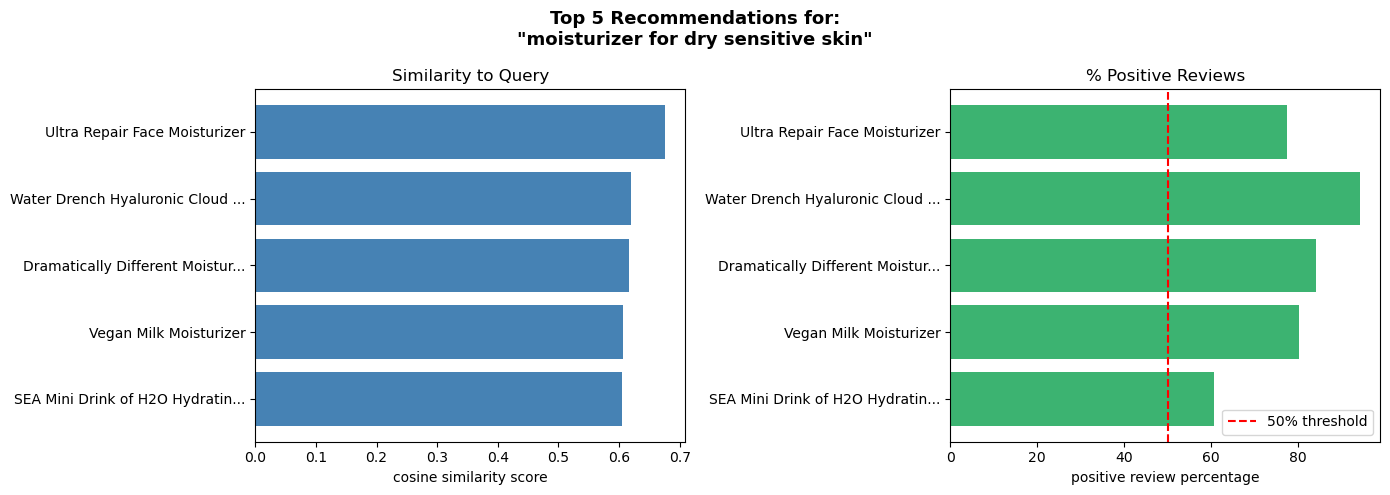

In [75]:
# visualising the results

# we visualise the top 5 recommendations for one query showing both similarity score and sentiment score side by side

query = "moisturizer for dry sensitive skin"
results = recommend_products(query, n=5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Top 5 Recommendations for:\n"{query}"', fontsize=13, fontweight='bold')

# shortening product names for readability
short_names = [name[:30] + '...' if len(name) > 30 else name 
               for name in results['product_name']]

# plot 1: similarity scores 
axes[0].barh(short_names[::-1], results['similarity_score'][::-1], color='steelblue')
axes[0].set_title('Similarity to Query')
axes[0].set_xlabel('cosine similarity score')

# plot 2: sentiment scores 
axes[1].barh(short_names[::-1], results['positive_pct'][::-1], color='mediumseagreen')
axes[1].set_title('% Positive Reviews')
axes[1].set_xlabel('positive review percentage')
axes[1].axvline(50, color='red', linestyle='--', label='50% threshold')
axes[1].legend()

plt.tight_layout()
plt.show()